# AI-Based Smart Energy Management for Industrial Machines
### Ensemble Anomaly Detection + Custom Retrieval-Augmented Generation (RAG)

**Google Colab implementation notebook**

This notebook builds a dataset-driven prototype in four layers:

1. Industrial sensor dataset acquisition and exploration.
2. Four anomaly detectors: Isolation Forest, KNN distance, PCA reconstruction error, and a PyTorch Autoencoder.
3. An equal-weight ensemble that combines calibrated anomaly scores.
4. CO2 NLP module: maintenance-log sentiment analysis and structured information extraction (entities, symptoms, sensor values and actions).
5. CO3 NLP module: LDA topic modeling over the extracted technical documents, plus optional multilingual language detection and Google Cloud Translation integration.
6. A custom RAG pipeline (document chunking → Sentence Transformers embeddings → FAISS retrieval → open-source Qwen LLM) that explains detected conditions using retrieved technical notes.

**Important scope and research-integrity notes**
- The primary dataset is SKAB, an industrial water-circulation testbed benchmark with current, voltage, temperature, pressure, vibration and flow measurements, plus anomaly labels.
- SKAB is not a factory-wide energy dataset. It supports industrial sensor anomaly-detection experiments, but it does not by itself prove electricity-cost savings or generalize to every motor/pump.
- The benchmark labels are used for evaluation, not as inputs to the unsupervised detectors.
- This is a dataset-driven prototype, not a live ESP32/sensor deployment.
- The RAG knowledge base loads public technical references from the U.S. Department of Energy and SKF when downloads succeed. These are general guidance documents, not manuals for the specific SKAB test rig; recommendations must remain cautious and evidence-based.
- Do not use generated guidance as a confirmed diagnosis or automatic shutdown command.
\n**CO coverage:** CO1 is addressed by PDF extraction, cleaning, chunking and embeddings; CO2 by sentiment analysis and information extraction; CO3 by topic modeling and optional cloud translation; CO4 by Qwen-based RAG and prompt engineering.

**Evaluation note:** No accuracy target is hard-coded or fabricated. The revised notebook selects thresholds on separate validation experiments and reports the actual performance on unseen test experiments. A 90% result can only be claimed if the held-out test metrics genuinely reach it.


## 0. Runtime setup

**Recommended:** Google Colab with a T4 GPU (Runtime → Change runtime type → T4 GPU). CPU is sufficient for the classical models; the Autoencoder and local LLM will run more slowly without a GPU.

The LLM cell is optional. The complete RAG retrieval pipeline and a transparent extractive fallback can still be demonstrated if model download or GPU memory is unavailable.

In [1]:
# Install dependencies
!pip -q install pandas numpy scipy scikit-learn matplotlib seaborn torch sentence-transformers faiss-cpu transformers accelerate pymupdf requests langdetect

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, sys, re, glob, json, math, random, warnings, subprocess, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import torch
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 1. Download the SKAB dataset

SKAB (Skoltech Anomaly Benchmark) contains multivariate sensor time series from an industrial water-circulation testbed. Its documented channels include motor current, voltage, engine/fluid temperature, pressure, vibration and flow rate. The repository describes 35 CSV experiments in version 0.9.

We clone the public repository and inspect its CSV files. If the repository layout changes, the inspection output helps identify the correct data folder.

In [3]:
SKAB_REPO = "https://github.com/waico/SKAB.git"
SKAB_DIR = Path("/content/SKAB")

if not SKAB_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", SKAB_REPO, str(SKAB_DIR)], check=True)

csv_paths = list((SKAB_DIR / "data").rglob("*.csv"))
print("CSV files found:", len(csv_paths))
for p in csv_paths[:15]:
    print(p.relative_to(SKAB_DIR))

CSV files found: 35
data/other/11.csv
data/other/4.csv
data/other/9.csv
data/other/2.csv
data/other/14.csv
data/other/10.csv
data/other/12.csv
data/other/5.csv
data/other/8.csv
data/other/6.csv
data/other/7.csv
data/other/13.csv
data/other/3.csv
data/other/1.csv
data/anomaly-free/anomaly-free.csv


### 1.1 Load and combine experiments

SKAB CSV files may use semicolon delimiters. The loader below detects separators, retains the source filename as an experiment group, and handles small schema variations. We exclude any file that is clearly a documentation/metadata table rather than a sensor experiment.

In [4]:
def read_skab_csv(path):
    # SKAB files are commonly semicolon-separated; sep=None also handles comma variants.
    try:
        df = pd.read_csv(path, sep=";", engine="python")
        if df.shape[1] <= 2:
            df = pd.read_csv(path, sep=None, engine="python")
    except Exception:
        df = pd.read_csv(path, sep=None, engine="python")

    df.columns = [str(c).strip() for c in df.columns]
    return df

frames = []
for path in csv_paths:
    try:
        part = read_skab_csv(path)
        lower_cols = {c.lower() for c in part.columns}
        if "anomaly" not in lower_cols:
            continue
        part["experiment_id"] = path.stem
        part["source_file"] = str(path)
        frames.append(part)
    except Exception as e:
        print("Skipped:", path.name, "|", repr(e))

if not frames:
    raise RuntimeError("No labelled SKAB CSV files found. Inspect the repository file list and adjust the loader.")

raw = pd.concat(frames, ignore_index=True, sort=False)
print("Combined shape:", raw.shape)
display(raw.head())
print("Columns:", raw.columns.tolist())

Combined shape: (37401, 13)


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint,experiment_id,source_file
0,2020-02-08 18:10:42,0.240983,0.287449,2.879000,0.054711,85.6509,31.3986,239.224,128.000,0.0,0.0,11,/content/SKAB/data/other/11.csv
1,2020-02-08 18:10:43,0.241153,0.285669,2.696420,0.054711,85.6603,31.4021,219.711,128.689,0.0,0.0,11,/content/SKAB/data/other/11.csv
2,2020-02-08 18:10:44,0.246551,0.287455,2.582570,0.382638,85.7871,31.4064,227.685,128.313,0.0,0.0,11,/content/SKAB/data/other/11.csv
3,2020-02-08 18:10:45,0.238680,0.282037,2.207200,0.382638,85.7108,31.4064,231.119,129.379,0.0,0.0,11,/content/SKAB/data/other/11.csv
4,2020-02-08 18:10:46,0.238926,0.285487,0.936421,0.382638,85.9412,31.4226,216.516,128.628,0.0,0.0,11,/content/SKAB/data/other/11.csv


Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint', 'experiment_id', 'source_file']


### 1.2 Standardize column names and inspect labels

We use the available numeric sensor channels. `anomaly` is the benchmark point-anomaly label (0 = normal, 1 = anomaly). `changepoint` is retained for reference but is not used as the target in this experiment.

In [5]:
# Normalize common column-name variations
rename_map = {}
for c in raw.columns:
    cl = c.strip().lower()
    if cl == "anomaly": rename_map[c] = "anomaly"
    elif cl == "changepoint": rename_map[c] = "changepoint"
    elif cl == "datetime": rename_map[c] = "datetime"
    elif "flow" in cl or "raterms" in cl: rename_map[c] = "FlowRate"
    elif cl == "current": rename_map[c] = "Current"
    elif cl == "voltage": rename_map[c] = "Voltage"
    elif cl == "pressure": rename_map[c] = "Pressure"
    elif cl == "temperature": rename_map[c] = "Temperature"
    elif cl == "thermocouple": rename_map[c] = "Thermocouple"
    elif "accelerometer1" in cl: rename_map[c] = "Vibration1"
    elif "accelerometer2" in cl: rename_map[c] = "Vibration2"

data = raw.rename(columns=rename_map).copy()
data["anomaly"] = pd.to_numeric(data["anomaly"], errors="coerce")
data = data[data["anomaly"].isin([0, 1])].copy()
data["anomaly"] = data["anomaly"].astype(int)

exclude = {"anomaly", "changepoint"}
numeric_features = [
    c for c in data.select_dtypes(include=np.number).columns
    if c not in exclude and data[c].notna().sum() > 0
]
# Keep numeric sensor columns only; remove accidental numeric metadata.
numeric_features = [c for c in numeric_features if c not in ["Unnamed: 0"]]

# Add time-series features within each experiment. Rolling windows use only the
# current and previous rows (no future information), and groups never cross experiments.
base_features = numeric_features.copy()
data = data.sort_values(["experiment_id", "datetime"] if "datetime" in data.columns else ["experiment_id"]).copy()
for col in base_features:
    grouped = data.groupby("experiment_id", sort=False)[col]
    data[f"{col}_diff1"] = grouped.diff().fillna(0)
    rolling_mean = grouped.transform(lambda s: s.rolling(window=5, min_periods=1).mean())
    rolling_std = grouped.transform(lambda s: s.rolling(window=5, min_periods=2).std()).fillna(0)
    data[f"{col}_deviation"] = data[col] - rolling_mean
    data[f"{col}_rolling_std"] = rolling_std

numeric_features = base_features + [
    f"{c}_{suffix}" for c in base_features
    for suffix in ("diff1", "deviation", "rolling_std")
]

print("Base sensor features:", base_features)
print("Engineered features:", len(numeric_features) - len(base_features))
print("Total model features:", len(numeric_features))
print("Rows:", len(data))
print("Anomaly rate:", round(data["anomaly"].mean(), 4))
display(data["anomaly"].value_counts().rename(index={0:"Normal",1:"Anomaly"}).to_frame("count"))

Base sensor features: ['Vibration1', 'Vibration2', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'FlowRate']
Engineered features: 24
Total model features: 32
Rows: 37401
Anomaly rate: 0.3494


,count
anomaly,
Normal,24334
Anomaly,13067


## 1.3 Clean the data and create train/validation/test experiment splits

A group-based split prevents rows from the same experiment appearing in more than one partition. We reserve separate experiment groups for training, validation and final testing. The four detectors are fitted only on normal training rows. Validation labels are used only to choose decision thresholds; final test labels are used only once for reporting.


In [6]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

data = data.replace([np.inf, -np.inf], np.nan).copy()
for c in numeric_features:
    data[c] = pd.to_numeric(data[c], errors="coerce")
data = data.dropna(subset=numeric_features, how="all").reset_index(drop=True)

groups = data["experiment_id"].astype(str).values
overall_rate = float(data["anomaly"].mean())

def choose_group_split(frame, test_size, seed, attempts=80):
    """Choose a group-disjoint split with both labels and representative label rates."""
    splitter = GroupShuffleSplit(n_splits=attempts, test_size=test_size, random_state=seed)
    best = None
    best_loss = float("inf")
    for left_idx, right_idx in splitter.split(frame, frame["anomaly"], groups=frame["experiment_id"].astype(str)):
        left_y = frame.iloc[left_idx]["anomaly"].to_numpy()
        right_y = frame.iloc[right_idx]["anomaly"].to_numpy()
        if len(np.unique(left_y)) < 2 or len(np.unique(right_y)) < 2:
            continue
        loss = abs(float(left_y.mean()) - overall_rate) + abs(float(right_y.mean()) - overall_rate)
        if loss < best_loss:
            best_loss = loss
            best = (left_idx, right_idx)
    if best is None:
        raise ValueError("Could not create group-disjoint train/validation/test splits containing both classes. Try a different seed or inspect experiment labels.")
    return best

trainval_idx, test_idx = choose_group_split(data, test_size=0.20, seed=SEED)
trainval_df = data.iloc[trainval_idx].copy()
test_df = data.iloc[test_idx].copy()

# Validation split is selected relative to the train/validation subset.
overall_rate = float(trainval_df["anomaly"].mean())
tr_rel, val_rel = choose_group_split(trainval_df, test_size=0.20, seed=SEED + 1)
train_all = trainval_df.iloc[tr_rel].copy()
val_df = trainval_df.iloc[val_rel].copy()

train_normal = train_all[train_all["anomaly"] == 0].copy()
if len(train_normal) < 100:
    raise ValueError("Too few normal training samples. Check the experiment split.")

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_normal = scaler.fit_transform(imputer.fit_transform(train_normal[numeric_features]))
X_val = scaler.transform(imputer.transform(val_df[numeric_features]))
X_test = scaler.transform(imputer.transform(test_df[numeric_features]))
y_val = val_df["anomaly"].to_numpy()
y_test = test_df["anomaly"].to_numpy()

print("Training experiments:", train_all["experiment_id"].nunique())
print("Validation experiments:", val_df["experiment_id"].nunique())
print("Testing experiments:", test_df["experiment_id"].nunique())
print("Normal training rows:", len(train_normal))
print("Validation rows / anomaly rate:", len(val_df), round(y_val.mean(), 4))
print("Test rows / anomaly rate:", len(test_df), round(y_test.mean(), 4))
print("No experiment is shared between train, validation and test.")


Training experiments: 9
Validation experiments: 3
Testing experiments: 4
Normal training rows: 14132
Validation rows / anomaly rate: 5643 0.3489
Test rows / anomaly rate: 10031 0.3492
No experiment is shared between train, validation and test.


## 2. Exploratory data analysis

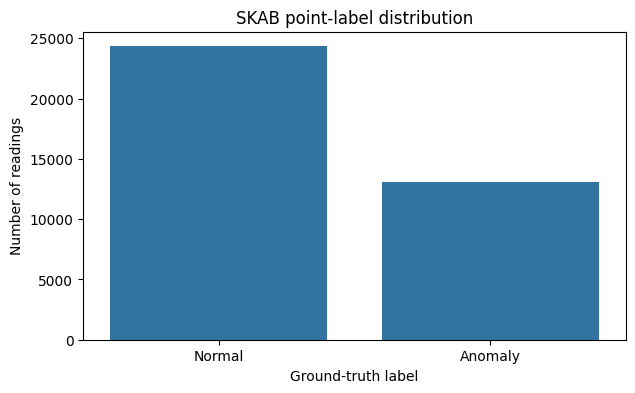

,count,mean,std,min,25%,50%,75%,max
Vibration1,37401.0,0.108317,0.133789,0.015752,0.027299,0.027881,0.216091,0.722747
Vibration2,37401.0,0.136305,0.150626,0.015505,0.040121,0.041440,0.263531,0.800498
Current,37401.0,1.464437,0.741118,0.149842,0.888148,1.222600,2.013360,3.318370
Pressure,37401.0,0.071326,0.260643,-1.257000,0.054711,0.054711,0.054711,1.694350
Temperature,37401.0,76.793848,8.831709,65.089000,69.054500,71.255100,86.332600,95.011400
Thermocouple,37401.0,26.054493,2.644086,22.020900,24.503800,24.974900,29.148500,33.415100
Voltage,37401.0,229.824241,10.932332,200.744000,223.808000,230.238000,236.152000,255.324000
FlowRate,37401.0,63.031317,42.519945,0.555512,32.000000,32.033700,125.321000,133.688000
Vibration1_diff1,37401.0,-0.000060,0.006038,-0.339291,-0.000542,-0.000006,0.000543,0.417716
Vibration1_deviation,37401.0,-0.000121,0.006299,-0.285851,-0.000337,0.000004,0.000337,0.336920


In [7]:
plt.figure(figsize=(7,4))
sns.countplot(x=data["anomaly"].map({0:"Normal",1:"Anomaly"}))
plt.title("SKAB point-label distribution")
plt.xlabel("Ground-truth label")
plt.ylabel("Number of readings")
plt.show()

display(data[numeric_features].describe().T)

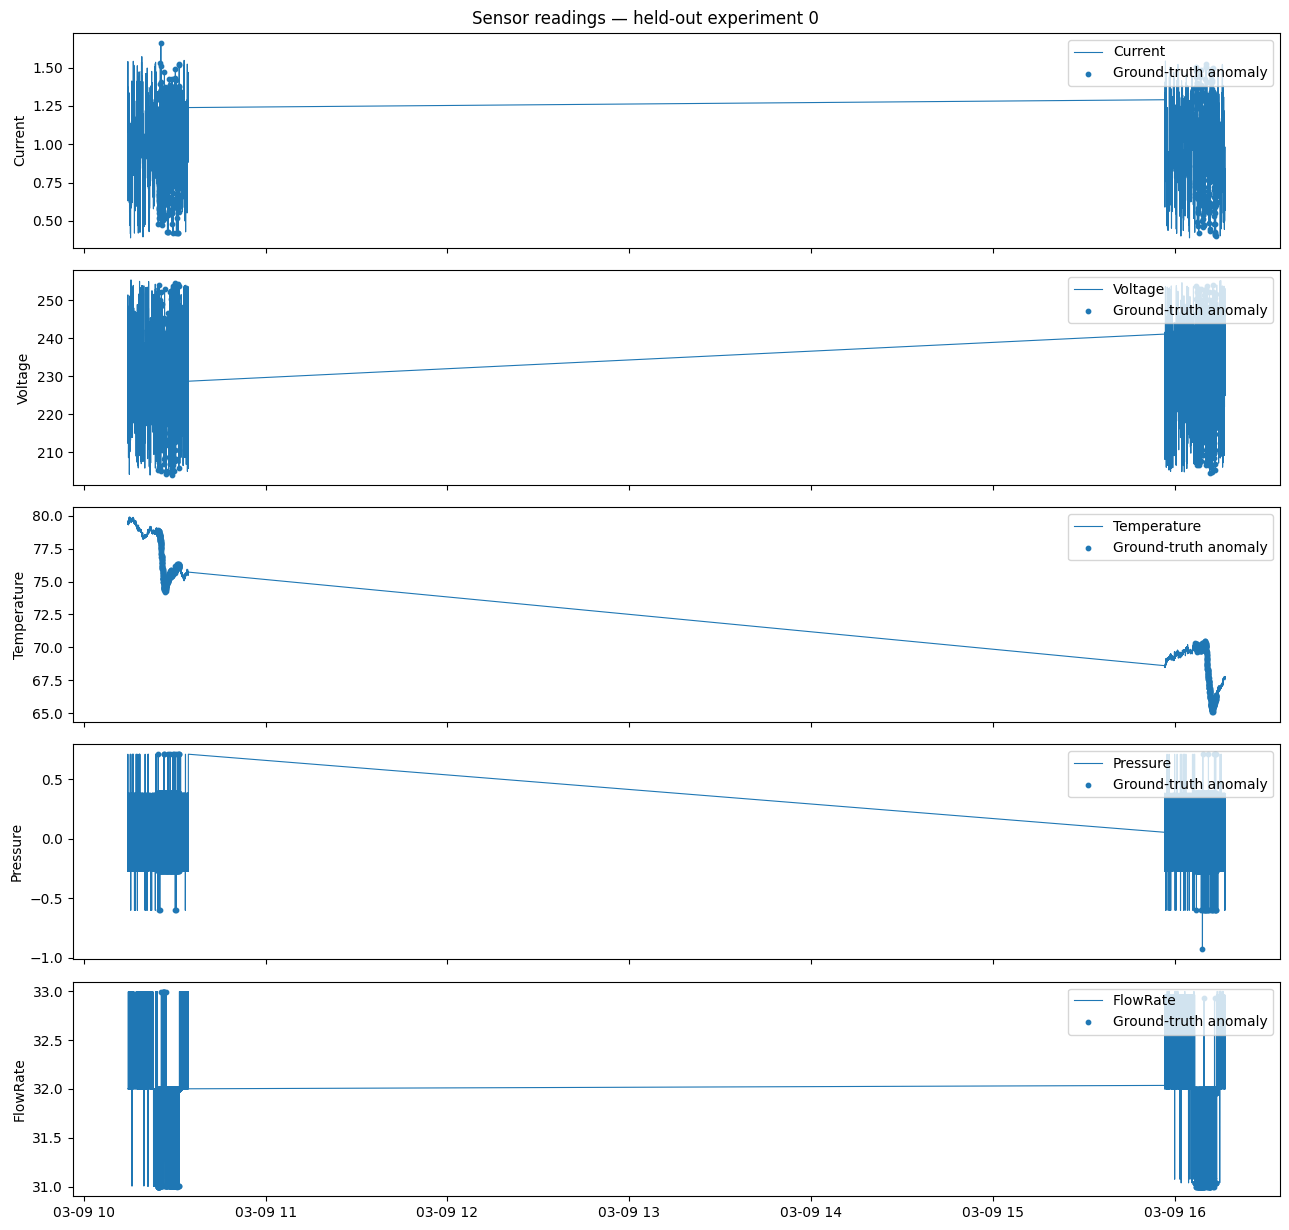

In [8]:
# Plot a sample held-out experiment over time (if datetime is available).
sample_exp = test_df["experiment_id"].iloc[0]
sample = test_df[test_df["experiment_id"] == sample_exp].copy()
if "datetime" in sample.columns:
    sample["datetime"] = pd.to_datetime(sample["datetime"], errors="coerce")
    sample = sample.sort_values("datetime")

plot_features = [c for c in ["Current","Voltage","Temperature","Pressure","FlowRate"] if c in sample.columns]
if plot_features:
    fig, axes = plt.subplots(len(plot_features), 1, figsize=(13, 2.5*len(plot_features)), sharex=True)
    if len(plot_features) == 1: axes = [axes]
    x = sample["datetime"] if "datetime" in sample.columns else np.arange(len(sample))
    for ax, col in zip(axes, plot_features):
        ax.plot(x, sample[col], linewidth=0.8, label=col)
        anomaly_mask = sample["anomaly"].to_numpy() == 1
        ax.scatter(np.asarray(x)[anomaly_mask], sample.loc[anomaly_mask, col], s=10, label="Ground-truth anomaly")
        ax.set_ylabel(col); ax.legend(loc="upper right")
    plt.suptitle(f"Sensor readings — held-out experiment {sample_exp}")
    plt.tight_layout()
    plt.show()
else:
    print("No expected sensor columns found for the example plot.")

## 3. Model 1 — Isolation Forest

Isolation Forest randomly partitions feature space. Unusual observations tend to be isolated in fewer splits. We invert `decision_function` so that larger values consistently mean “more anomalous”.

In [9]:
from sklearn.ensemble import IsolationForest

if_model = IsolationForest(
    n_estimators=400,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    random_state=SEED,
    n_jobs=-1
)
if_model.fit(X_train_normal)
score_if_train = -if_model.decision_function(X_train_normal)
score_if_val = -if_model.decision_function(X_val)
score_if_test = -if_model.decision_function(X_test)
print("Isolation Forest scores calculated.")


Isolation Forest scores calculated.


## 4. Model 2 — KNN distance anomaly detector

KNN is used here as a distance-based detector, not a classifier. We calculate the average distance to the k nearest normal training observations. A test point far from normal neighbours receives a high anomaly score.

In [10]:
from sklearn.neighbors import NearestNeighbors

K = min(10, len(X_train_normal) - 1)
knn_model = NearestNeighbors(n_neighbors=K + 1, metric="euclidean", n_jobs=-1)
knn_model.fit(X_train_normal)

knn_train_dist, _ = knn_model.kneighbors(X_train_normal)
score_knn_train = knn_train_dist[:, 1:].mean(axis=1)
score_knn_val = knn_model.kneighbors(X_val, n_neighbors=K)[0].mean(axis=1)
score_knn_test = knn_model.kneighbors(X_test, n_neighbors=K)[0].mean(axis=1)
print("KNN scores calculated; K =", K)


KNN scores calculated; K = 10


## 5. Model 3 — PCA reconstruction-error detector

PCA compresses correlated sensor variables into fewer components. We reconstruct the original standardized readings from the retained components. A large reconstruction error indicates a pattern that differs from the learned normal operating structure.

In [11]:
from sklearn.decomposition import PCA

n_components = min(0.95, max(1, len(numeric_features)-1))
pca_model = PCA(n_components=n_components, random_state=SEED)
pca_model.fit(X_train_normal)

def pca_reconstruction_error(model, X):
    X_proj = model.transform(X)
    X_recon = model.inverse_transform(X_proj)
    return np.mean((X - X_recon)**2, axis=1)

score_pca_train = pca_reconstruction_error(pca_model, X_train_normal)
score_pca_val = pca_reconstruction_error(pca_model, X_val)
score_pca_test = pca_reconstruction_error(pca_model, X_test)
print("PCA components:", pca_model.n_components_)
print("Explained variance:", round(pca_model.explained_variance_ratio_.sum(), 4))


PCA components: 16
Explained variance: 0.953


## 6. Model 4 — PyTorch Autoencoder

An Autoencoder learns to reconstruct normal sensor readings. It is trained only on normal training observations. A high reconstruction error on a new reading is treated as an anomaly score.

The network is intentionally compact for Colab and a third-year project demonstration.

In [12]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = X_train_normal.shape[1]

class SensorAutoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 8)
        )
        self.decoder = nn.Sequential(
            nn.Linear(8, 16), nn.ReLU(),
            nn.Linear(16, 32), nn.ReLU(),
            nn.Linear(32, input_dim)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

ae_model = SensorAutoencoder(input_dim).to(device)
optimizer = torch.optim.Adam(ae_model.parameters(), lr=5e-4, weight_decay=1e-5)
criterion = nn.MSELoss()
train_tensor = torch.tensor(X_train_normal, dtype=torch.float32)
loader = DataLoader(TensorDataset(train_tensor), batch_size=256, shuffle=True)

EPOCHS = 50
for epoch in range(EPOCHS):
    ae_model.train()
    losses = []
    for (batch,) in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        recon = ae_model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | loss={np.mean(losses):.6f}")

def ae_scores(X, batch_size=1024):
    ae_model.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = torch.tensor(X[start:start+batch_size], dtype=torch.float32, device=device)
            recon = ae_model(xb)
            out.extend(torch.mean((recon-xb)**2, dim=1).cpu().numpy())
    return np.asarray(out)

score_ae_train = ae_scores(X_train_normal)
score_ae_val = ae_scores(X_val)
score_ae_test = ae_scores(X_test)


Epoch 10/50 | loss=0.358321
Epoch 20/50 | loss=0.233997
Epoch 30/50 | loss=0.170825
Epoch 40/50 | loss=0.135261
Epoch 50/50 | loss=0.113715


## 7. Calibrate anomaly scores and choose thresholds on validation data

Raw scores from different detectors have different scales. For each detector, we divide its scores by the 99th percentile of its normal-training scores. The threshold is then selected on the separate validation experiments by maximizing validation F1. The final test set is not used to tune thresholds.

This is a **semi-supervised threshold-selection protocol**: detectors learn from normal training readings, while labelled validation data chooses the operating threshold. It does not guarantee 90% accuracy. Report the actual held-out test metrics without changing thresholds after seeing test results.


In [22]:
from sklearn.metrics import precision_recall_curve, balanced_accuracy_score
import numpy as np
import pandas as pd

train_score_map = {
    "IsolationForest": score_if_train,
    "KNN": score_knn_train,
    "PCA": score_pca_train,
    "Autoencoder": score_ae_train
}
val_score_map = {
    "IsolationForest": score_if_val,
    "KNN": score_knn_val,
    "PCA": score_pca_val,
    "Autoencoder": score_ae_val
}
test_score_map = {
    "IsolationForest": score_if_test,
    "KNN": score_knn_test,
    "PCA": score_pca_test,
    "Autoencoder": score_ae_test
}

# Normalize each detector using only its normal-training score distribution.
calibration_thresholds = {
    name: max(float(np.quantile(scores, 0.99)), 1e-9)
    for name, scores in train_score_map.items()
}
normalized_val_scores = {
    name: scores / calibration_thresholds[name]
    for name, scores in val_score_map.items()
}
normalized_test_scores = {
    name: scores / calibration_thresholds[name]
    for name, scores in test_score_map.items()
}

def best_threshold(y_true, scores):
    # Candidate thresholds come only from validation scores. Balanced accuracy
    # prevents the majority normal class from dominating threshold selection.
    scores = np.asarray(scores, dtype=float)
    candidates = np.unique(np.quantile(scores, np.linspace(0.01, 0.99, 250)))
    if len(candidates) == 0:
        return float(np.median(scores))
    values = [balanced_accuracy_score(y_true, (scores >= t).astype(int)) for t in candidates]
    return float(candidates[int(np.argmax(values))])

# Thresholds selected independently for the four models on validation data.
decision_thresholds = {
    name: best_threshold(y_val, scores)
    for name, scores in normalized_val_scores.items()
}

# Equal-weight ensemble; threshold also selected on validation data.
val_ensemble_score = np.mean(
    np.column_stack(list(normalized_val_scores.values())), axis=1
)
test_ensemble_score = np.mean(
    np.column_stack(list(normalized_test_scores.values())), axis=1
)
decision_thresholds["EqualWeightEnsemble"] = best_threshold(
    y_val, val_ensemble_score
)

print("Normal-training score scaling values:")
display(pd.Series(calibration_thresholds, name="scale").to_frame())
print("Validation-selected balanced-accuracy thresholds:")
display(pd.Series(decision_thresholds, name="threshold").to_frame())

score_table = pd.DataFrame(normalized_test_scores)
score_table["EnsembleScore"] = test_ensemble_score
score_table["GroundTruth"] = y_test
display(score_table.head())

Normal-training score scaling values:


,scale
IsolationForest,0.067100
KNN,5.386658
PCA,0.393353
Autoencoder,0.838611


Validation-selected balanced-accuracy thresholds:


,threshold
IsolationForest,-0.502943
KNN,0.616420
PCA,0.324694
Autoencoder,0.421610
EqualWeightEnsemble,0.376411


,IsolationForest,KNN,PCA,Autoencoder,EnsembleScore,GroundTruth
0,-1.208473,0.347318,0.071426,0.098274,-0.172864,0
1,-1.373247,0.340353,0.094044,0.071969,-0.216720,0
2,-1.064014,0.383227,0.124925,0.137985,-0.104469,0
3,-1.199034,0.376021,0.135630,0.197081,-0.122576,0
4,-1.130863,0.329051,0.125758,0.083259,-0.148199,0


## 8. Evaluation: compare all four detectors and the ensemble

For every model, report accuracy, precision, recall, F1, specificity, balanced accuracy, Matthews correlation coefficient, ROC-AUC and average precision. Confusion matrices are plotted separately for all four models and the ensemble. Accuracy alone can be misleading on imbalanced anomaly data, so recall, F1 and average precision are important too.


In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    confusion_matrix, matthews_corrcoef, classification_report
)

def evaluate_scores(y_true, scores, threshold):
    pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    metrics = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "BalancedAccuracy": balanced_accuracy_score(y_true, pred),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC_AUC": roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan,
        "AveragePrecision": average_precision_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan
    }
    return metrics, pred

all_test_scores = dict(normalized_test_scores)
all_test_scores["EqualWeightEnsemble"] = test_ensemble_score

results = {}
predictions = {}
for name, scores in all_test_scores.items():
    metrics, pred = evaluate_scores(y_test, scores, decision_thresholds[name])
    results[name] = metrics
    predictions[name] = pred

results_df = pd.DataFrame(results).T.sort_values("F1", ascending=False)
display(results_df.style.format("{:.4f}").highlight_max(axis=0))
print("Best F1 model:", results_df["F1"].idxmax())
print("Best accuracy model:", results_df["Accuracy"].idxmax())


,Accuracy,Precision,Recall,F1,Specificity,BalancedAccuracy,MCC,ROC_AUC,AveragePrecision
IsolationForest,0.6223,0.3863,0.1387,0.2042,0.8817,0.5102,0.0295,0.5320,0.4006
EqualWeightEnsemble,0.6703,0.8311,0.0702,0.1295,0.9923,0.5313,0.1763,0.5237,0.3977
KNN,0.6694,0.8106,0.0697,0.1283,0.9913,0.5305,0.1702,0.5006,0.3901
Autoencoder,0.6688,0.8267,0.0654,0.1212,0.9926,0.5290,0.1688,0.5029,0.3912
PCA,0.6692,0.8464,0.0645,0.1199,0.9937,0.5291,0.1725,0.4951,0.3850


Best F1 model: IsolationForest
Best accuracy model: EqualWeightEnsemble


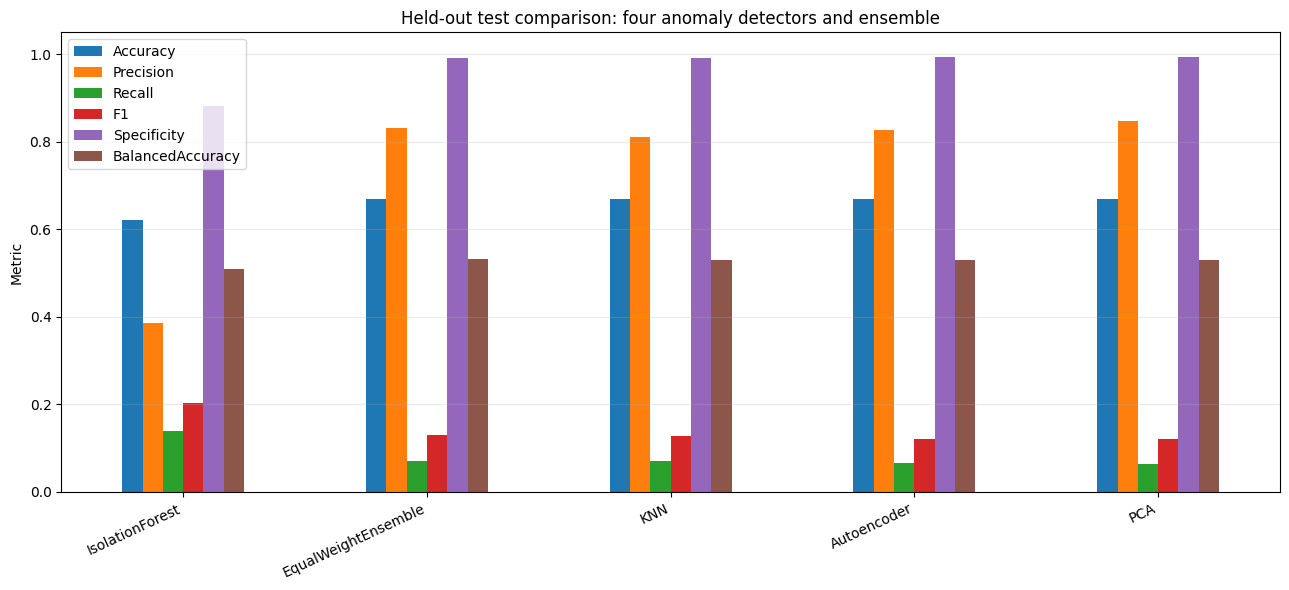

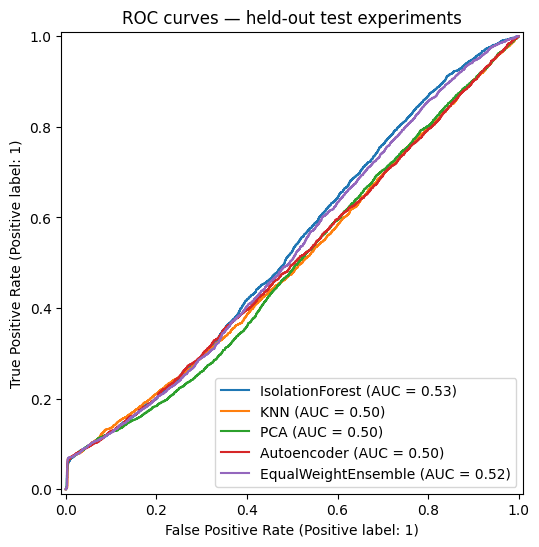

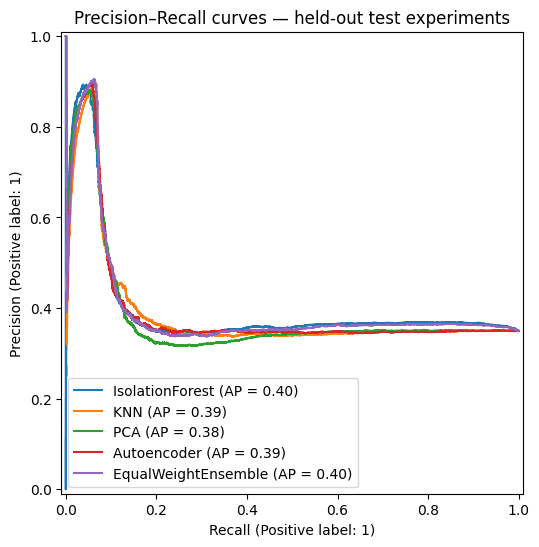

In [15]:
## 8.1 Metric comparison charts and ROC / Precision-Recall curves

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "Specificity", "BalancedAccuracy"]
results_df[metrics_to_plot].plot(kind="bar", figsize=(13, 6))
plt.title("Held-out test comparison: four anomaly detectors and ensemble")
plt.ylabel("Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

if len(np.unique(y_test)) == 2:
    from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, scores in all_test_scores.items():
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax)
    ax.set_title("ROC curves — held-out test experiments")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    for name, scores in all_test_scores.items():
        PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
    ax.set_title("Precision–Recall curves — held-out test experiments")
    plt.show()


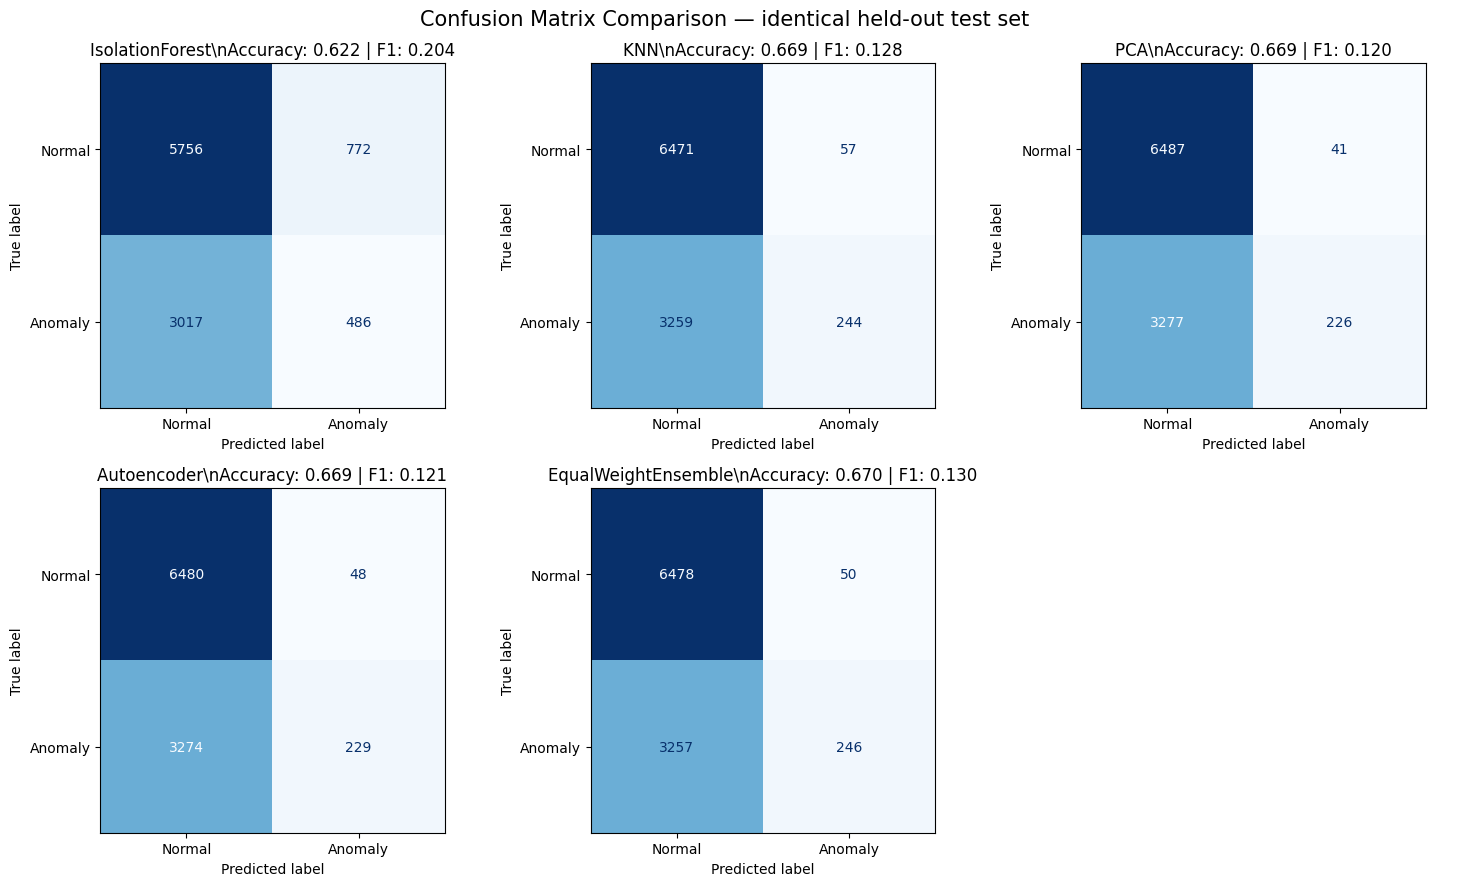

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Model,,,,,,,,
IsolationForest,5756.0000,772.0000,3017.0000,486.0000,0.6223,0.3863,0.1387,0.2042
KNN,6471.0000,57.0000,3259.0000,244.0000,0.6694,0.8106,0.0697,0.1283
PCA,6487.0000,41.0000,3277.0000,226.0000,0.6692,0.8464,0.0645,0.1199
Autoencoder,6480.0000,48.0000,3274.0000,229.0000,0.6688,0.8267,0.0654,0.1212
EqualWeightEnsemble,6478.0000,50.0000,3257.0000,246.0000,0.6703,0.8311,0.0702,0.1295


\n======================================================================
IsolationForest
Threshold: -0.502943
              precision    recall  f1-score   support

      Normal       0.66      0.88      0.75      6528
     Anomaly       0.39      0.14      0.20      3503

    accuracy                           0.62     10031
   macro avg       0.52      0.51      0.48     10031
weighted avg       0.56      0.62      0.56     10031

\n======================================================================
KNN
Threshold: 0.61642
              precision    recall  f1-score   support

      Normal       0.67      0.99      0.80      6528
     Anomaly       0.81      0.07      0.13      3503

    accuracy                           0.67     10031
   macro avg       0.74      0.53      0.46     10031
weighted avg       0.72      0.67      0.56     10031

\n======================================================================
PCA
Threshold: 0.324694
              precision    recall  f1-score

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Same held-out test rows and same label order for every detector.
model_order = ["IsolationForest", "KNN", "PCA", "Autoencoder", "EqualWeightEnsemble"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, name in zip(axes, model_order):
    pred = predictions[name]
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Anomaly"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\\nAccuracy: {accuracy_score(y_test, pred):.3f} | F1: {f1_score(y_test, pred, zero_division=0):.3f}")

axes[-1].axis("off")
fig.suptitle("Confusion Matrix Comparison — identical held-out test set", fontsize=15)
plt.tight_layout()
plt.show()

# Compact numeric comparison of TN, FP, FN and TP for all models.
cm_rows = []
for name in model_order:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name], labels=[0, 1]).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "Accuracy": accuracy_score(y_test, predictions[name]),
                    "Precision": precision_score(y_test, predictions[name], zero_division=0),
                    "Recall": recall_score(y_test, predictions[name], zero_division=0),
                    "F1": f1_score(y_test, predictions[name], zero_division=0)})
confusion_comparison_df = pd.DataFrame(cm_rows).set_index("Model")
display(confusion_comparison_df.style.format("{:.4f}"))

for name in model_order:
    print("\\n" + "=" * 70)
    print(name)
    print("Threshold:", round(decision_thresholds[name], 6))
    print(classification_report(
        y_test, predictions[name], labels=[0, 1],
        target_names=["Normal", "Anomaly"], zero_division=0
    ))


## 9. Inspect a detected event and create a structured incident record

The RAG system will receive a compact record generated from the ensemble output. The sensor readings are actual held-out SKAB measurements. Any severity category below is a prototype rule based on the normalized ensemble score, not a validated industrial safety limit.

## Why the project has two separate data sources

- **SKAB dataset:** numerical time-series sensor measurements and anomaly labels. Used to train/test anomaly detectors.
- **RAG document collection:** external technical documents (DOE O&M guide and SKF bearing maintenance handbook). Used only to retrieve explanatory maintenance context.

We do not merge PDF text into the sensor CSVs. At answer time, the language model receives the detected sensor evidence plus retrieved passages and their source/page metadata.

In [17]:
test_results = test_df.reset_index(drop=True).copy()
test_results["EnsembleScore"] = test_ensemble_score
test_results["EnsemblePrediction"] = predictions["EqualWeightEnsemble"]
for model_name in normalized_test_scores:
    test_results[model_name + "_Score"] = normalized_test_scores[model_name]
    test_results[model_name + "_Prediction"] = predictions[model_name]

detected = test_results[test_results["EnsemblePrediction"] == 1]
if len(detected) == 0:
    event_row = test_results.iloc[int(np.argmax(test_results["EnsembleScore"]))]
    print("No event exceeded the validation-selected threshold; showing the highest-scoring test reading.")
else:
    event_row = detected.sort_values("EnsembleScore", ascending=False).iloc[0]

sensor_snapshot = {c: float(event_row[c]) for c in numeric_features if pd.notna(event_row[c])}
incident = {
    "experiment_id": str(event_row["experiment_id"]),
    "ensemble_score": float(event_row["EnsembleScore"]),
    "model_votes": {
        name: int(event_row[name + "_Prediction"])
        for name in normalized_test_scores
    },
    "sensor_readings": sensor_snapshot,
    "ground_truth_label_for_evaluation_only": int(event_row["anomaly"])
}
print(json.dumps(incident, indent=2))


{
  "experiment_id": "8",
  "ensemble_score": 333.7484588321423,
  "model_votes": {
    "IsolationForest": 1,
    "KNN": 1,
    "PCA": 1,
    "Autoencoder": 1
  },
  "sensor_readings": {
    "Vibration1": 0.589896,
    "Vibration2": 0.673331,
    "Current": 2.88884,
    "Pressure": 0.382638,
    "Temperature": 88.0159,
    "Thermocouple": 29.8215,
    "Voltage": 232.829,
    "FlowRate": 127.684,
    "Vibration1_diff1": 0.368823,
    "Vibration1_deviation": 0.297591,
    "Vibration1_rolling_std": 0.1663788328318841,
    "Vibration2_diff1": 0.41213700000000003,
    "Vibration2_deviation": 0.3298644,
    "Vibration2_rolling_std": 0.18440296073355217,
    "Current_diff1": 0.32111,
    "Current_deviation": 0.5445988000000002,
    "Current_rolling_std": 0.8111741850843126,
    "Pressure_diff1": 0.32792699999999997,
    "Pressure_deviation": 0.3279269999999999,
    "Pressure_rolling_std": 0.23187940543416105,
    "Temperature_diff1": 0.12359999999999616,
    "Temperature_deviation": 0.0162999

# Part II — Custom RAG implementation (no paid API)

## 10. Build a document-based technical knowledge base

This version downloads real, publicly accessible technical references into a separate RAG knowledge base. These are NOT added to the SKAB CSV dataset.

Sources:
1. **U.S. Department of Energy (DOE), Operations & Maintenance Best Practices Guide, Release 3.0** — includes motor condition checks, temperature/vibration monitoring, lubrication, alignment, ventilation and motor-system efficiency.
2. **SKF Bearing Maintenance Handbook** — manufacturer reference covering bearing inspection, condition monitoring, lubrication, temperature and vibration-related maintenance.

The notebook extracts text from the PDFs, preserves page numbers, chunks the content, embeds it and indexes it in FAISS. The references provide general guidance, not a diagnosis for the SKAB test rig. Always follow equipment-specific manuals and qualified maintenance procedures.

In [18]:
from pathlib import Path
import requests
import fitz  # PyMuPDF
import pandas as pd

knowledge_dir = Path("/content/industrial_knowledge")
knowledge_dir.mkdir(exist_ok=True)

REFERENCE_SOURCES = [
    {
        "source_id": "DOE-OM-2010",
        "title": "Operations & Maintenance Best Practices Guide, Release 3.0",
        "publisher": "U.S. Department of Energy, Federal Energy Management Program",
        "url": "https://www.energy.gov/sites/default/files/2020/04/f74/omguide_complete_w-eo-disclaimer.pdf",
        "filename": "DOE_Operations_Maintenance_Best_Practices.pdf"
    },
    {
        "source_id": "SKF-BEARING-HANDBOOK",
        "title": "SKF Bearing Maintenance Handbook",
        "publisher": "SKF",
        "url": "https://www.skf.com/binaries/pub12/Images/0901d1968013be94-SKF-bearing-maintenance-handbook---10001_1-EN%281%29_tcm_12-463040.pdf",
        "filename": "SKF_Bearing_Maintenance_Handbook.pdf"
    }
]

def download_reference_pdf(source, timeout=90):
    path = knowledge_dir / source["filename"]
    if not path.exists() or path.stat().st_size < 100_000:
        print("Downloading:", source["title"])
        response = requests.get(
            source["url"], timeout=timeout,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        response.raise_for_status()
        if not response.content.startswith(b"%PDF"):
            raise ValueError("Downloaded content is not a PDF: " + source["title"])
        path.write_bytes(response.content)
    return path

# Keep one record per PDF page so RAG can cite document and page.
document_records = []
download_log = []

for source in REFERENCE_SOURCES:
    try:
        pdf_path = download_reference_pdf(source)
        pdf = fitz.open(pdf_path)
        extracted_pages = 0
        for page_no, page in enumerate(pdf, start=1):
            page_text = page.get_text("text").strip()
            if len(page_text) > 80:
                document_records.append({
                    "source": source["source_id"],
                    "title": source["title"],
                    "publisher": source["publisher"],
                    "url": source["url"],
                    "page": page_no,
                    "text": page_text
                })
                extracted_pages += 1
        download_log.append({
            "source": source["source_id"],
            "status": "loaded",
            "pages_extracted": extracted_pages,
            "file": str(pdf_path)
        })
    except Exception as e:
        print(f"WARNING: Could not load {source['source_id']}: {type(e).__name__}: {e}")
        download_log.append({
            "source": source["source_id"],
            "status": "failed — check source URL or retry download",
            "pages_extracted": 0,
            "file": ""
        })

display(pd.DataFrame(download_log))
print("Total reference pages extracted:", len(document_records))
loaded_ids = [item["source"] for item in download_log if item["status"] == "loaded"]
print("Successfully loaded reference documents:", loaded_ids)
if len(loaded_ids) < len(REFERENCE_SOURCES):
    print("WARNING: Some reference PDFs could not be downloaded. The RAG corpus will contain only successfully loaded sources.")

if not document_records:
    raise RuntimeError(
        "No reference PDF text was extracted. Check internet access and the reference PDF URLs, then rerun this cell."
    )


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Downloading: Operations & Maintenance Best Practices Guide, Release 3.0
Downloading: SKF Bearing Maintenance Handbook


,source,status,pages_extracted,file
0,DOE-OM-2010,loaded,302,/content/industrial_knowledge/DOE_Operations_M...
1,SKF-BEARING-HANDBOOK,loaded,427,/content/industrial_knowledge/SKF_Bearing_Main...


Total reference pages extracted: 729
Successfully loaded reference documents: ['DOE-OM-2010', 'SKF-BEARING-HANDBOOK']


## 11. Chunk documents and create embeddings

We chunk the extracted PDF text while retaining document ID and page number. Sentence Transformers converts each chunk into a vector, and FAISS stores those vectors for similarity search. This makes retrieval traceable: every returned passage can identify the document and page it came from.

In [19]:
from sentence_transformers import SentenceTransformer
import faiss

def chunk_text(text, chunk_words=180, overlap_words=35):
    words = text.split()
    chunks = []
    step = max(1, chunk_words - overlap_words)
    for start in range(0, len(words), step):
        part = words[start:start+chunk_words]
        if len(part) >= 25:
            chunks.append(" ".join(part))
    return chunks

rag_chunks = []
for record in document_records:
    for chunk_no, chunk in enumerate(chunk_text(record["text"]), start=1):
        rag_chunks.append({
            "source": record["source"],
            "title": record["title"],
            "publisher": record["publisher"],
            "url": record["url"],
            "page": record["page"],
            "chunk_id": chunk_no,
            "text": chunk
        })

if not rag_chunks:
    raise RuntimeError("No RAG chunks were created. Check PDF text extraction.")

print("Total RAG chunks:", len(rag_chunks))
print("Unique documents:", sorted(set(item["source"] for item in rag_chunks)))
display(pd.DataFrame(rag_chunks)[["source", "page", "chunk_id", "text"]].head())


Total RAG chunks: 1944
Unique documents: ['DOE-OM-2010', 'SKF-BEARING-HANDBOOK']


,source,page,chunk_id,text
0,DOE-OM-2010,3,1,Release 3.0 Operations & Maintenance Best Prac...
1,DOE-OM-2010,4,1,Disclaimer This report was sponsored by the Un...
2,DOE-OM-2010,5,1,Preface  This Operations and Maintenance (O&M...
3,DOE-OM-2010,5,2,"energy, water, and building commissioning mana..."
4,DOE-OM-2010,5,3,can be achieved with minimal cash outlays. In ...


In [20]:
EMBED_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBED_MODEL_NAME)

corpus_texts = [item["text"] for item in rag_chunks]
corpus_embeddings = embedding_model.encode(
    corpus_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

embedding_dim = corpus_embeddings.shape[1]
vector_index = faiss.IndexFlatIP(embedding_dim)  # cosine similarity because vectors are normalized
vector_index.add(corpus_embeddings)

print("FAISS vectors:", vector_index.ntotal)
print("Embedding dimension:", embedding_dim)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/61 [00:00<?, ?it/s]

FAISS vectors: 1944
Embedding dimension: 384


## CO2 — Sentiment analysis and information extraction from maintenance text

This section connects NLP to the same industrial-maintenance workflow as the anomaly detector and RAG system.

- **Sentiment analysis:** a pretrained Transformer sentiment classifier analyzes an operator's written maintenance note. Its polarity is only the tone of the text; it is **not** a machine-fault severity score.
- **Information extraction:** a pretrained Named Entity Recognition (NER) model extracts named entities. Domain-specific rules additionally identify machine/component terms, fault symptoms, maintenance actions and numeric sensor measurements with units.
- The demo note below is illustrative. Replace it with a real, anonymized maintenance log during the demonstration. The SKAB dataset contains sensor measurements, not human-written maintenance logs.
- Model outputs are evaluated qualitatively with a visible example. Do not claim validated industrial sentiment accuracy without a labelled maintenance-log test set.

The resulting structured extraction is attached to the current incident and can be passed into the RAG query and Qwen prompt.

In [24]:
from transformers import pipeline
import json, re

# Replace this illustrative text with an anonymized operator/maintenance note if available.
operator_note = (
    "The pump motor is showing excessive vibration and high temperature. "
    "Current reached 8.4 A and temperature reached 76 C. "
    "The technician recommends inspecting bearing lubrication and alignment."
)

# Transformer-based sentiment classification. First run downloads the model.
SENTIMENT_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment_classifier = pipeline(
    "sentiment-analysis", model=SENTIMENT_MODEL,
    device=-1
)
sentiment_result = sentiment_classifier(operator_note, truncation=True)[0]
# Sanitize float types in sentiment results
sentiment_result["score"] = float(sentiment_result["score"])

# Transformer-based general-purpose NER. NER labels are model predictions and
# may not recognize industrial terminology; domain rules below complement it.
NER_MODEL = "dslim/bert-base-NER"
ner_pipeline = pipeline(
    "token-classification", model=NER_MODEL, aggregation_strategy="simple",
    device=-1
)
ner_entities = ner_pipeline(operator_note)

# Sanitize any numpy float32 values in ner_entities to avoid JSON serialization errors
sanitized_ner_entities = []
for ent in ner_entities:
    sanitized_ent = ent.copy()
    for k, v in sanitized_ent.items():
        if hasattr(v, "item"):  # Convert numpy scalars
            sanitized_ent[k] = v.item()
    sanitized_ner_entities.append(sanitized_ent)

# Domain-specific information extraction for industrial maintenance notes.
text_lower = operator_note.lower()
component_terms = ["pump", "motor", "bearing", "shaft", "valve", "fan", "compressor"]
symptom_terms = ["vibration", "overheating", "high temperature", "noise", "leakage", "pressure drop", "overcurrent"]
action_terms = ["inspect", "inspection", "lubrication", "alignment", "replace", "repair", "clean", "tighten", "monitor"]

found_components = [term for term in component_terms if term in text_lower]
found_symptoms = [term for term in symptom_terms if term in text_lower]
found_actions = [term for term in action_terms if term in text_lower]

# Extract number + unit pairs such as 8.4 A, 76 C, 2.1 bar, or 5 mm/s.
measurement_pattern = re.compile(
    r"(?P<value>\d+(?:\.\d+)?)\s*(?P<unit>°?\s*[A-Za-z]+(?:/[A-Za-z]+)?)"
)
measurements = [m.groupdict() for m in measurement_pattern.finditer(operator_note)]

co2_extraction = {
    "sentiment": sentiment_result,
    "ner_entities": sanitized_ner_entities,
    "equipment_components": found_components,
    "reported_symptoms": found_symptoms,
    "maintenance_actions": found_actions,
    "measurements": measurements
}

# Attach the NLP result to the selected anomaly incident for downstream RAG.
incident["nlp_analysis"] = co2_extraction
print("OPERATOR NOTE:\n", operator_note)
print("\nSENTIMENT RESULT:", sentiment_result)
print("\nSTRUCTURED INFORMATION EXTRACTION:")
print(json.dumps(co2_extraction, indent=2))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


OPERATOR NOTE:
 The pump motor is showing excessive vibration and high temperature. Current reached 8.4 A and temperature reached 76 C. The technician recommends inspecting bearing lubrication and alignment.

SENTIMENT RESULT: {'label': 'NEGATIVE', 'score': 0.9942465424537659}

STRUCTURED INFORMATION EXTRACTION:
{
  "sentiment": {
    "label": "NEGATIVE",
    "score": 0.9942465424537659
  },
  "ner_entities": [
    {
      "entity_group": "MISC",
      "score": 0.8963335156440735,
      "word": "A",
      "start": 88,
      "end": 89
    },
    {
      "entity_group": "MISC",
      "score": 0.9938581585884094,
      "word": "C",
      "start": 117,
      "end": 118
    }
  ],
  "equipment_components": [
    "pump",
    "motor",
    "bearing"
  ],
  "reported_symptoms": [
    "vibration",
    "high temperature"
  ],
  "maintenance_actions": [
    "inspect",
    "lubrication",
    "alignment"
  ],
  "measurements": [
    {
      "value": "8.4",
      "unit": "A"
    },
    {
      "value

## CO3 — Topic modeling and multilingual NLP for the technical knowledge base

This section uses the PDF pages already extracted for RAG (`document_records`), so it is part of the same project knowledge base rather than a separate unrelated dataset.

**Part A — Topic modeling:** TF-IDF features and Latent Dirichlet Allocation (LDA) discover recurring themes in the DOE and SKF technical-document corpus. The notebook displays the top terms per topic and the dominant topic for each source page. Topic names are inferred from keywords and should be interpreted by a human.

**Part B — Multilingual workflow:** language detection identifies the input language. If a Google Cloud Translation API key is configured, the text is translated to English so it can be sent to the existing English RAG retriever. The cloud translation step is optional because Google Cloud requires an enabled project, billing/API access and a key. Without credentials, language detection and the LDA topic-modeling demonstration still run.

This implementation does not claim speech transcription; the project accepts written maintenance text.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Build topic-model documents from the same extracted PDF pages used by RAG.
topic_docs = [
    {"source": rec["source"], "page": rec["page"], "text": rec["text"]}
    for rec in document_records if len(rec["text"].split()) >= 30
]
if len(topic_docs) < 2:
    raise ValueError("Not enough extracted PDF pages for topic modeling. Check the PDF download/extraction cell.")

topic_vectorizer = TfidfVectorizer(
    stop_words="english", max_df=0.95, min_df=2,
    max_features=5000, ngram_range=(1, 2)
)
X_topics = topic_vectorizer.fit_transform([d["text"] for d in topic_docs])
N_TOPICS = min(5, max(2, len(topic_docs) // 10))
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS, random_state=SEED, learning_method="batch", max_iter=10
)
doc_topic_matrix = lda_model.fit_transform(X_topics)
feature_names = topic_vectorizer.get_feature_names_out()

print(f"LDA fitted on {len(topic_docs)} extracted PDF pages; topics={N_TOPICS}")
for topic_idx, topic_weights in enumerate(lda_model.components_):
    top_ids = topic_weights.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_ids]
    print(f"\nTopic {topic_idx + 1}: " + ", ".join(top_words))

page_topics = pd.DataFrame({
    "source": [d["source"] for d in topic_docs],
    "page": [d["page"] for d in topic_docs],
    "dominant_topic": doc_topic_matrix.argmax(axis=1) + 1,
    "topic_confidence": doc_topic_matrix.max(axis=1)
})
display(page_topics.head(15))

# Store topic-model metadata for the report and allow topic-aware RAG queries.
TOPIC_KEYWORDS = {
    topic_idx + 1: [feature_names[i] for i in lda_model.components_[topic_idx].argsort()[-10:][::-1]]
    for topic_idx in range(N_TOPICS)
}


LDA fitted on 715 extracted PDF pages; topics=5

Topic 1: seal, hmv, fig, housings, sleeve, hydraulic nut, seals, installing, w33, remove

Topic 2: energy, maintenance, equipment, water, air, boiler, steam, cost, building, efficiency

Topic 3: fig, bearing, ring, shaft, bearings, mounting, roller, housing, inner, units

Topic 4: tsn, 321, 314, 312, 317, 318, 311, 327, 333, 313

Topic 5: grease, skf, bearing, oil, lubrication, bearings, lubricant, damage, seals, rolling


,source,page,dominant_topic,topic_confidence
0,DOE-OM-2010,3,2,0.877510
1,DOE-OM-2010,4,2,0.871467
2,DOE-OM-2010,5,2,0.923370
3,DOE-OM-2010,7,2,0.900247
4,DOE-OM-2010,9,2,0.887414
5,DOE-OM-2010,10,2,0.836760
6,DOE-OM-2010,11,2,0.781400
7,DOE-OM-2010,12,2,0.912580
8,DOE-OM-2010,13,2,0.737245
9,DOE-OM-2010,14,2,0.718710


## 12. Implement retrieval and inspect retrieved evidence

In [26]:
def retrieve(query, top_k=4):
    q_emb = embedding_model.encode(
        [query], convert_to_numpy=True, normalize_embeddings=True
    ).astype("float32")
    scores, indices = vector_index.search(q_emb, min(top_k, len(rag_chunks)))
    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx >= 0:
            item = rag_chunks[int(idx)].copy()
            item["similarity"] = float(score)
            results.append(item)
    return results

example_query = "What does the maintenance guidance say about monitoring motor temperature and vibration?"
retrieved = retrieve(example_query, top_k=4)
for r in retrieved:
    print(
        f'{r["source"]} | page={r["page"]} | '
        f'similarity={r["similarity"]:.3f} | {r["title"]}'
    )
    print(r["text"][:600])
    print("Source:", r["url"], "\n")


DOE-OM-2010 | page=237 | similarity=0.707 | Operations & Maintenance Best Practices Guide, Release 3.0
for better maintenance planning and less unexpected failures. Predictive maintenance programs for motors observe the temperatures, vibrations, and other data to determine a time for an overhaul or replacement of the motor (Barnish et al. 2001). Consult each motor’s instructions for maintenance guidelines. Motors are not all the same. Be careful not to think that what is good for one is good for all. For example, some motors require a periodic greasing of the bearings and some do not (Operators and Consulting Services Incorporated 2001). O&M Best Practices Guide, Release 3.0 9.113
Source: https://www.energy.gov/sites/default/files/2020/04/f74/omguide_complete_w-eo-disclaimer.pdf 

DOE-OM-2010 | page=237 | similarity=0.669 | Operations & Maintenance Best Practices Guide, Release 3.0
• Check ventilation systems for excessive air. - Re-sheave fan if air is excessive. - Downsize motors, if

# Multilingual text input example — edit this with a maintenance query in Hindi/Marathi/etc.
multilingual_query = "मोटर का तापमान बढ़ रहा है और कंपन असामान्य है।"

try:
    from langdetect import detect
    detected_language = detect(multilingual_query)
except Exception as e:
    detected_language = "unknown"
    print("Language detection issue:", repr(e))

print("Detected language code:", detected_language)

# Optional cloud translation using Google Cloud Translation Basic (v2).
# Create/enable a Google Cloud Translation project and store its API key in Colab Secrets
# as GOOGLE_TRANSLATE_API_KEY, or paste it into the variable below for a short demo.
GOOGLE_TRANSLATE_API_KEY = ""  # Keep blank if cloud credentials are not configured.
translated_query_en = None

if GOOGLE_TRANSLATE_API_KEY.strip():
    translation_url = "https://translation.googleapis.com/language/translate/v2"
    response = requests.post(
        translation_url,
        params={"key": GOOGLE_TRANSLATE_API_KEY},
        data={"q": multilingual_query, "target": "en", "format": "text"},
        timeout=30
    )
    response.raise_for_status()
    translation_payload = response.json()["data"]["translations"][0]
    translated_query_en = translation_payload["translatedText"]
    print("Google Cloud Translation output:", translated_query_en)
    print("Cloud-detected source language:", translation_payload.get("detectedSourceLanguage", "not returned"))

    # Connect translated text to the existing RAG retriever.
    if "retrieve" in globals() and translated_query_en:
        multilingual_retrieval = retrieve(translated_query_en, top_k=4)
        print("\nRetrieved technical evidence for translated query:")
        for item in multilingual_retrieval:
            print(f"{item['source']} | page {item['page']} | similarity={item['similarity']:.3f}")
else:
    print("Cloud translation skipped: configure GOOGLE_TRANSLATE_API_KEY to call Google Cloud Translation.")
    print("The LDA topic model above is fully executable without a cloud key.")


In [27]:
# Multilingual text input example — edit this with a maintenance query in Hindi/Marathi/etc.
multilingual_query = "मोटर का तापमान बढ़ रहा है और कंपन असामान्य है।"

try:
    from langdetect import detect
    detected_language = detect(multilingual_query)
except Exception as e:
    detected_language = "unknown"
    print("Language detection issue:", repr(e))

print("Detected language code:", detected_language)

# Optional cloud translation using Google Cloud Translation Basic (v2).
# Create/enable a Google Cloud Translation project and store its API key in Colab Secrets
# as GOOGLE_TRANSLATE_API_KEY, or paste it into the variable below for a short demo.
GOOGLE_TRANSLATE_API_KEY = ""  # Keep blank if cloud credentials are not configured.
translated_query_en = None

if GOOGLE_TRANSLATE_API_KEY.strip():
    translation_url = "https://translation.googleapis.com/language/translate/v2"
    response = requests.post(
        translation_url,
        params={"key": GOOGLE_TRANSLATE_API_KEY},
        data={"q": multilingual_query, "target": "en", "format": "text"},
        timeout=30
    )
    response.raise_for_status()
    translation_payload = response.json()["data"]["translations"][0]
    translated_query_en = translation_payload["translatedText"]
    print("Google Cloud Translation output:", translated_query_en)
    print("Cloud-detected source language:", translation_payload.get("detectedSourceLanguage", "not returned"))

    # Connect translated text to the existing RAG retriever.
    if "retrieve" in globals() and translated_query_en:
        multilingual_retrieval = retrieve(translated_query_en, top_k=4)
        print("\nRetrieved technical evidence for translated query:")
        for item in multilingual_retrieval:
            print(f"{item['source']} | page {item['page']} | similarity={item['similarity']:.3f}")
else:
    print("Cloud translation skipped: configure GOOGLE_TRANSLATE_API_KEY to call Google Cloud Translation.")
    print("The LDA topic model above is fully executable without a cloud key.")


Detected language code: hi
Cloud translation skipped: configure GOOGLE_TRANSLATE_API_KEY to call Google Cloud Translation.
The LDA topic model above is fully executable without a cloud key.


## 13. Load an open-source local LLM (Qwen2.5-1.5B-Instruct)

This model is downloaded from Hugging Face and runs in the Colab runtime; no Gemini/OpenAI inference API is called. The model is relatively small, but generation quality is not guaranteed to match larger hosted models. If memory is limited, skip this cell and use the retrieval-only fallback in the next section.

Model card: https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct

In [28]:
USE_LOCAL_LLM = True  # Set False to run retrieval + evidence-based fallback only.

llm = None
tokenizer = None

if USE_LOCAL_LLM:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model_kwargs = {"low_cpu_mem_usage": True}
    if torch.cuda.is_available():
        model_kwargs.update({"torch_dtype": torch.float16, "device_map": "auto"})
    else:
        model_kwargs.update({"torch_dtype": torch.float32})
    llm = AutoModelForCausalLM.from_pretrained(MODEL_ID, **model_kwargs)
    print("Loaded:", MODEL_ID)
else:
    print("Local LLM disabled. RAG retrieval and fallback response remain available.")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-1.5B-Instruct


## 14. Generate a grounded explanation from retrieved context

The prompt instructs the model to distinguish observed sensor values from possible causes, avoid claiming a confirmed diagnosis, and cite the retrieved source IDs. For safety, recommendations are inspection prompts and not instructions to work on live electrical equipment.

In [29]:
def build_incident_query(incident):
    readings = incident["sensor_readings"]
    reading_text = ", ".join(f"{k}={v:.3f}" for k, v in readings.items())
    return (
        "Industrial pump/motor anomaly investigation. "
        f"Sensor readings: {reading_text}. "
        "Explain possible interpretations and safe next checks using technical maintenance guidance."
    )

def generate_answer(incident, top_k=4, max_new_tokens=220):
    query = build_incident_query(incident)
    docs = retrieve(query, top_k=top_k)
    context = "\n\n".join(
        f'[Source {d["source"]}, page {d["page"]}, chunk {d["chunk_id"]}] {d["text"]}'
        for d in docs
    )

    prompt = f"""You are an industrial condition-monitoring assistant.
Use ONLY the evidence in the context for technical claims.
The sensor data indicates an anomaly, not a confirmed fault.
Separate observed facts from possible explanations.
Give cautious next-check recommendations. Do not recommend touching live electrical equipment,
bypassing safeguards, or automatically shutting down machinery.
If evidence is insufficient, say so. Cite the actual retrieved source ID and page, for example [DOE-OM-2010, p. 12] or [SKF-BEARING-HANDBOOK, p. 8]. Do not invent source IDs or page numbers.

INCIDENT DATA:
{json.dumps(incident["sensor_readings"], indent=2)}
Ensemble anomaly score: {incident["ensemble_score"]:.3f}

RETRIEVED CONTEXT:
{context}

Respond with:
1. What was observed
2. Possible explanations (not diagnosis)
3. Recommended safe checks
4. Evidence used (exact source IDs and page numbers)
"""

    if llm is None:
        answer = (
            "LLM generation is disabled. Retrieved evidence for this incident:\n\n" +
            "\n\n".join(f'[{d["source"]}] {d["text"]}' for d in docs)
        )
    else:
        messages = [
            {"role": "system", "content": "You are a careful industrial maintenance information assistant."},
            {"role": "user", "content": prompt}
        ]
        # Extract the input_ids tensor from the dictionary returned by the tokenizer
        tokenized = tokenizer.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        input_ids = tokenized["input_ids"].to(llm.device)
        attention_mask = tokenized["attention_mask"].to(llm.device) if "attention_mask" in tokenized else None

        with torch.no_grad():
            output = llm.generate(
                input_ids,
                attention_mask=attention_mask,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.08,
                pad_token_id=tokenizer.eos_token_id
            )
        answer = tokenizer.decode(output[0][input_ids.shape[-1]:], skip_special_tokens=True)

    return answer, docs, query

answer, evidence, rag_query = generate_answer(incident)
print("RAG QUERY:\n", rag_query)
print("\nGENERATED GUIDANCE:\n", answer)
print("\nRETRIEVED SOURCES:")
for item in evidence:
    print(item["source"], "similarity:", round(item["similarity"], 3))

RAG QUERY:
 Industrial pump/motor anomaly investigation. Sensor readings: Vibration1=0.590, Vibration2=0.673, Current=2.889, Pressure=0.383, Temperature=88.016, Thermocouple=29.822, Voltage=232.829, FlowRate=127.684, Vibration1_diff1=0.369, Vibration1_deviation=0.298, Vibration1_rolling_std=0.166, Vibration2_diff1=0.412, Vibration2_deviation=0.330, Vibration2_rolling_std=0.184, Current_diff1=0.321, Current_deviation=0.545, Current_rolling_std=0.811, Pressure_diff1=0.328, Pressure_deviation=0.328, Pressure_rolling_std=0.232, Temperature_diff1=0.124, Temperature_deviation=0.016, Temperature_rolling_std=0.062, Thermocouple_diff1=-0.005, Thermocouple_deviation=-0.003, Thermocouple_rolling_std=0.005, Voltage_diff1=4.258, Voltage_deviation=3.904, Voltage_rolling_std=15.278, FlowRate_diff1=0.366, FlowRate_deviation=0.083, FlowRate_rolling_std=0.289. Explain possible interpretations and safe next checks using technical maintenance guidance.

GENERATED GUIDANCE:
 ### 1. What was observed:

The 

## 15. Interactive assistant for a selected sensor event

Ask a question about the detected event. The question is combined with the event readings, then the custom retriever finds relevant knowledge chunks before the LLM responds.

In [30]:
def ask_energy_assistant(question, incident_record=incident, top_k=4):
    query = build_incident_query(incident_record) + " User question: " + question
    docs = retrieve(query, top_k=top_k)
    context = "\n\n".join(
        f'[Source {d["source"]}, page {d["page"]}] {d["text"]}' for d in docs
    )
    prompt = f"""Answer the user's industrial energy-management question using the retrieved context.
Do not invent a confirmed root cause. Distinguish measured observations from possibilities.
Use cautious, safe recommendations and cite the exact retrieved source IDs and page numbers; do not invent citations.
Incident readings: {json.dumps(incident_record["sensor_readings"])}
NLP-extracted maintenance context: {json.dumps(incident_record.get("nlp_analysis", {}), indent=2)}
Ensemble score: {incident_record["ensemble_score"]:.3f}
Retrieved context:
{context}
User question: {question}
"""
    if llm is None:
        return "LLM is disabled. Relevant retrieved evidence:\n" + context, docs
    messages = [
        {"role":"system","content":"You are a careful industrial energy assistant."},
        {"role":"user","content":prompt}
    ]
    # Extract input_ids and attention_mask correctly from the returned dictionary
    tokenized = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True
    )
    input_ids = tokenized["input_ids"].to(llm.device)
    attention_mask = tokenized["attention_mask"].to(llm.device) if "attention_mask" in tokenized else None

    with torch.no_grad():
        out = llm.generate(
            input_ids,
            attention_mask=attention_mask,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True), docs

# Try a question:
response, sources = ask_energy_assistant("What should the maintenance team inspect first, and what evidence supports it?")
print(response)
print("\nSources:", [s["source"] for s in sources])

Based on the incident readings and NLP-extracted maintenance context, the maintenance team should prioritize inspecting the pump and motor components.

The key points supporting this recommendation are:

1. **High Temperature**: The highest temperature reading (88.0159°C) suggests potential overheating issues, which could lead to further complications like increased wear and tear on critical components such as bearings and motors.

2. **Vibration Analysis**: Both vibration sensors recorded significant deviations (0.589896 and 0.673331), indicating abnormal vibration levels. This could suggest bearing issues, misalignment, or other mechanical problems within the pump and motor assembly.

3. **Inspection Prioritization**: Given the high temperatures and significant vibration readings, the inspection of the pump and motor components seems to be the most urgent step. These areas are likely where the majority of

Sources: ['DOE-OM-2010', 'DOE-OM-2010', 'DOE-OM-2010', 'SKF-BEARING-HANDBOOK']

## CO4 Extension A — Structured AI Report Generation

This section extends the CO4 generative AI module by enforcing **structured JSON output** using prompt engineering, schema validation, and deterministic parsing/fallback logic.

Instead of free-form prose, the LLM (or extractive fallback when `llm is None`) produces a machine-readable JSON maintenance report containing:
- `machine_health_status`: `"Healthy"` or `"Anomalous"` (derived from the ensemble anomaly detector)
- `detected_anomalies`: list of sensor channels showing notable deviations from normal training baselines
- `possible_causes`: cautious, non-diagnostic hypotheses grounded strictly in retrieved RAG technical documents
- `risk_severity`: `"Low"`, `"Medium"`, or `"High"` based on calibrated ensemble score and model consensus
- `recommended_maintenance_actions`: safe, inspection-only maintenance steps (never direct machinery actuation or live-electrical intervention)
- `evidence_citations`: exact source IDs and page numbers from the FAISS RAG retrieval step


In [31]:
import json
import re

REPORT_SCHEMA_KEYS = [
    "machine_health_status",
    "detected_anomalies",
    "possible_causes",
    "risk_severity",
    "recommended_maintenance_actions",
    "evidence_citations",
]

def summarize_sensor_deviations(sensor_readings, top_n=4):
    """Identify base sensor channels with the largest standardized shift vs. normal training data."""
    deviations = []
    for idx, col in enumerate(base_features):
        if col not in sensor_readings:
            continue
        val = float(sensor_readings[col])
        mean_val = float(scaler.mean_[idx])
        std_val = max(float(scaler.scale_[idx]), 1e-6)
        z_score = (val - mean_val) / std_val
        deviations.append({
            "sensor": col,
            "observed_value": round(val, 4),
            "normal_mean": round(mean_val, 4),
            "z_score": round(z_score, 2),
            "direction": "elevated" if z_score > 0 else "depressed"
        })
    deviations.sort(key=lambda x: abs(x["z_score"]), reverse=True)
    return deviations[:top_n]

def compute_risk_severity(ensemble_score, threshold, model_votes):
    """Determine cautious risk severity tier from calibrated ensemble score and detector consensus."""
    vote_count = sum(int(v) for v in model_votes.values())
    ratio = ensemble_score / max(threshold, 1e-6)
    if ensemble_score < threshold and vote_count == 0:
        return "Low"
    if ratio >= 1.5 or vote_count >= 3:
        return "High"
    return "Medium"

def extract_json_object(raw_text):
    """Extract and parse the first valid JSON object from LLM text output."""
    cleaned = raw_text.strip()
    # Strip markdown code fences if present
    cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned)
    cleaned = re.sub(r"\s*```$", "", cleaned)
    try:
        parsed = json.loads(cleaned)
        if isinstance(parsed, dict):
            return parsed
    except json.JSONDecodeError:
        pass

    # Fallback: find outermost {...} block
    start = cleaned.find("{")
    end = cleaned.rfind("}")
    if start != -1 and end != -1 and end > start:
        try:
            parsed = json.loads(cleaned[start:end + 1])
            if isinstance(parsed, dict):
                return parsed
        except json.JSONDecodeError:
            pass
    return None

def build_fallback_structured_report(incident_record, deviations, docs):
    """Deterministic, RAG-grounded fallback report if local LLM is disabled or JSON parsing fails."""
    threshold = float(decision_thresholds["EqualWeightEnsemble"])
    score = float(incident_record["ensemble_score"])
    is_anomalous = score >= threshold or sum(incident_record["model_votes"].values()) > 0
    severity = compute_risk_severity(score, threshold, incident_record["model_votes"])

    detected = [
        f'{d["sensor"]}: {d["observed_value"]} ({d["direction"]}, z={d["z_score"]:+.2f} vs normal baseline {d["normal_mean"]})'
        for d in deviations if abs(d["z_score"]) >= 1.0
    ]
    if not detected and deviations:
        d0 = deviations[0]
        detected = [f'{d0["sensor"]}: {d0["observed_value"]} (z={d0["z_score"]:+.2f} vs normal baseline {d0["normal_mean"]})']

    citations = [f'{d["source"]}, p. {d["page"]}' for d in docs]
    snippets = [d["text"][:180].strip() + "..." for d in docs[:2]]

    possible_causes = [
        f"Potential mechanical, hydraulic, or load-related variation reflected in {', '.join(d['sensor'] for d in deviations[:2])} (hypothesis only; requires physical inspection)."
    ]
    if snippets:
        possible_causes.append(f"Reference note context: {snippets[0]}")

    recommended_actions = [
        "Verify sensor calibration and data acquisition integrity before scheduling intrusive work.",
        "Perform visual and thermal/vibration walkdown inspection following lockout/tagout (LOTO) safety procedures.",
        "Review recent operating logs (valve position, flow load, and maintenance notes) for correlated changes."
    ]
    if "nlp_analysis" in incident_record and incident_record["nlp_analysis"].get("maintenance_actions"):
        nlp_acts = ", ".join(incident_record["nlp_analysis"]["maintenance_actions"])
        recommended_actions.append(f"Follow up on operator-noted inspection items: {nlp_acts}.")

    return {
        "machine_health_status": "Anomalous" if is_anomalous else "Healthy",
        "detected_anomalies": detected,
        "possible_causes": possible_causes,
        "risk_severity": severity,
        "recommended_maintenance_actions": recommended_actions,
        "evidence_citations": citations
    }

def generate_structured_maintenance_report(incident_record, top_k=4, max_new_tokens=320):
    """Generate and validate a structured JSON maintenance report using RAG + Qwen2.5-1.5B-Instruct."""
    deviations = summarize_sensor_deviations(incident_record["sensor_readings"], top_n=4)
    query = build_incident_query(incident_record)
    docs = retrieve(query, top_k=top_k)
    fallback_report = build_fallback_structured_report(incident_record, deviations, docs)

    if llm is None or tokenizer is None:
        return fallback_report, "fallback_llm_disabled"

    context = "\n\n".join(
        f'[{d["source"]}, p. {d["page"]}] {d["text"]}' for d in docs
    )
    schema_template = {
        "machine_health_status": fallback_report["machine_health_status"],
        "detected_anomalies": ["<sensor and observed deviation>"],
        "possible_causes": ["<cautious hypothesis grounded in context, not confirmed diagnosis>"],
        "risk_severity": fallback_report["risk_severity"],
        "recommended_maintenance_actions": ["<safe inspection step only; no automatic shutdown or live electrical contact>"],
        "evidence_citations": ["<SourceID, p. X>"]
    }

    prompt = f"""Generate a JSON maintenance report for an industrial pump/motor monitoring event.
Output ONLY a single valid JSON object matching the exact keys shown below. Do not include markdown prose outside the JSON.

Rules:
- Base technical claims ONLY on the RETRIEVED CONTEXT.
- Keep 'machine_health_status' as "{fallback_report['machine_health_status']}" and 'risk_severity' as "{fallback_report['risk_severity']}".
- Distinguish sensor observations from possible causes (never state a confirmed diagnosis).
- Only recommend safe inspection/verification actions (never recommend automatic shutdown or touching live electrical parts).
- Cite actual source IDs and pages from the context in 'evidence_citations'.

TARGET JSON FORMAT:
{json.dumps(schema_template, indent=2)}

SENSOR DEVIATIONS:
{json.dumps(deviations, indent=2)}

ENSEMBLE SCORE: {incident_record["ensemble_score"]:.3f} (threshold={decision_thresholds["EqualWeightEnsemble"]:.3f})
MODEL VOTES: {json.dumps(incident_record["model_votes"])}

RETRIEVED CONTEXT:
{context}
"""

    try:
        messages = [
            {"role": "system", "content": "You are a strict JSON generator for industrial predictive maintenance reports. Return valid JSON only."},
            {"role": "user", "content": prompt}
        ]
        tokenized = tokenizer.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        input_ids = tokenized["input_ids"].to(llm.device)
        attention_mask = tokenized.get("attention_mask", None)
        if attention_mask is not None:
            attention_mask = attention_mask.to(llm.device)

        with torch.no_grad():
            output = llm.generate(
                input_ids,
                attention_mask=attention_mask,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.05,
                pad_token_id=tokenizer.eos_token_id
            )
        raw_response = tokenizer.decode(output[0][input_ids.shape[-1]:], skip_special_tokens=True)
        parsed = extract_json_object(raw_response)

        if parsed is None:
            return fallback_report, "fallback_json_parse_error"

        # Validate & sanitize required fields while preserving deterministic safety/status fields
        validated = {}
        for key in REPORT_SCHEMA_KEYS:
            if key in ("machine_health_status", "risk_severity"):
                validated[key] = fallback_report[key]
            elif key in parsed and isinstance(parsed[key], list) and len(parsed[key]) > 0:
                validated[key] = [str(item) for item in parsed[key]]
            else:
                validated[key] = fallback_report[key]

        return validated, "llm_json_validated"
    except Exception as e:
        print("Structured LLM generation failed; using deterministic RAG fallback:", repr(e))
        return fallback_report, "fallback_exception"

structured_report, generation_mode = generate_structured_maintenance_report(incident)
print("Generation mode:", generation_mode)
print(json.dumps(structured_report, indent=2))


Generation mode: fallback_json_parse_error
{
  "machine_health_status": "Anomalous",
  "detected_anomalies": [
    "Vibration1: 0.5899 (elevated, z=+5.33 vs normal baseline 0.0962)",
    "Vibration2: 0.6733 (elevated, z=+5.17 vs normal baseline 0.1234)",
    "Current: 2.8888 (elevated, z=+1.91 vs normal baseline 1.4777)",
    "FlowRate: 127.684 (elevated, z=+1.50 vs normal baseline 64.6864)"
  ],
  "possible_causes": [
    "Potential mechanical, hydraulic, or load-related variation reflected in Vibration1, Vibration2 (hypothesis only; requires physical inspection).",
    "Reference note context: allows for an accurate, non-contact assessment of temperature. Applications for pumps include assessments on bearing assemblies at the impeller housing and motor system connections..."
  ],
  "risk_severity": "High",
  "recommended_maintenance_actions": [
    "Verify sensor calibration and data acquisition integrity before scheduling intrusive work.",
    "Perform visual and thermal/vibration w

## CO4 Extension B — Agentic AI for Predictive Maintenance

This section implements a tool-calling **Predictive Maintenance AI Agent** that orchestrates the existing anomaly detection pipeline, FAISS RAG retriever, and LLM reasoning engine in a transparent, auditable loop.

### Agent Workflow & Tool Registry
1. **`check_sensor_readings(row_index)`**: Reads multivariate sensor measurements (and engineered rolling features) from a held-out SKAB test sample and summarizes channel deviations against normal baselines.
2. **`run_anomaly_detection(row_index)`**: Evaluates the sample across all four calibrated detectors (**Isolation Forest**, **KNN**, **PCA**, and **PyTorch Autoencoder**) plus the **Equal-Weight Ensemble** using the validation-selected thresholds.
3. **`retrieve_technical_docs(query, top_k)`**: Queries the existing Sentence Transformers + FAISS vector index to pull relevant DOE / SKF maintenance guidance.
4. **`generate_maintenance_recommendations(incident_record)`**: Synthesizes a structured maintenance assessment using CO4 Extension A (`generate_structured_maintenance_report`).
5. **`build_prioritized_action_plan(report, incident_record)`**: Produces a ranked, safety-bounded maintenance action plan (`P1 Immediate Inspection`, `P2 Diagnostic Verification`, `P3 Routine Monitoring`).

> **Safety & Governance Guardrail:** This agent operates strictly in **advisory mode**. It outputs prioritized human inspection recommendations and explicitly prohibits autonomous machine control, remote actuator switching, or live electrical intervention.


In [32]:
from datetime import datetime, timezone

class PredictiveMaintenanceAgent:
    """
    Advisory Predictive Maintenance Agent using explicit tool/function calling,
    calibrated ensemble anomaly detection, FAISS RAG retrieval, and LLM reasoning.
    Strictly advisory: never issues direct control commands to industrial equipment.
    """

    def __init__(self, test_frame, feature_cols):
        self.test_frame = test_frame.reset_index(drop=True)
        self.feature_cols = feature_cols
        self.execution_trace = []
        self.tools = {
            "check_sensor_readings": self.tool_check_sensor_readings,
            "run_anomaly_detection": self.tool_run_anomaly_detection,
            "retrieve_technical_docs": self.tool_retrieve_technical_docs,
            "generate_maintenance_recommendations": self.tool_generate_maintenance_recommendations,
            "build_prioritized_action_plan": self.tool_build_prioritized_action_plan,
        }

    def _log_step(self, step_num, tool_name, tool_input, tool_output_summary):
        entry = {
            "step": step_num,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "tool": tool_name,
            "input": tool_input,
            "output_summary": tool_output_summary,
        }
        self.execution_trace.append(entry)
        print(f"[Agent Step {step_num}] Tool='{tool_name}' -> {tool_output_summary}")

    # --- Tool 1: Check machine sensor readings ---
    def tool_check_sensor_readings(self, row_index):
        if row_index < 0 or row_index >= len(self.test_frame):
            raise IndexError(f"row_index {row_index} out of bounds for test set (0..{len(self.test_frame)-1}).")
        row = self.test_frame.iloc[row_index]
        readings = {c: float(row[c]) for c in self.feature_cols if pd.notna(row[c])}
        deviations = summarize_sensor_deviations(readings, top_n=4)
        return {
            "row_index": int(row_index),
            "experiment_id": str(row["experiment_id"]),
            "datetime": str(row["datetime"]) if "datetime" in row and pd.notna(row["datetime"]) else "N/A",
            "sensor_readings": readings,
            "top_deviations": deviations,
        }

    # --- Tool 2: Call existing anomaly detection models ---
    def tool_run_anomaly_detection(self, row_index):
        # Reuse precomputed calibrated test scores if available; otherwise score on the fly
        if "EnsembleScore" in self.test_frame.columns and row_index < len(self.test_frame):
            row = self.test_frame.iloc[row_index]
            model_scores = {
                name: float(row[name + "_Score"])
                for name in calibration_thresholds
            }
            model_votes = {
                name: int(row[name + "_Prediction"])
                for name in calibration_thresholds
            }
            ensemble_score = float(row["EnsembleScore"])
            ensemble_pred = int(row["EnsemblePrediction"])
        else:
            x_raw = self.test_frame.iloc[[row_index]][self.feature_cols]
            x_scaled = scaler.transform(imputer.transform(x_raw))
            raw_scores = {
                "IsolationForest": float(-if_model.decision_function(x_scaled)[0]),
                "KNN": float(knn_model.kneighbors(x_scaled, n_neighbors=K)[0].mean(axis=1)[0]),
                "PCA": float(pca_reconstruction_error(pca_model, x_scaled)[0]),
                "Autoencoder": float(ae_scores(x_scaled)[0]),
            }
            model_scores = {
                name: raw_scores[name] / calibration_thresholds[name]
                for name in raw_scores
            }
            model_votes = {
                name: int(model_scores[name] >= decision_thresholds[name])
                for name in model_scores
            }
            ensemble_score = float(np.mean(list(model_scores.values())))
            ensemble_pred = int(ensemble_score >= decision_thresholds["EqualWeightEnsemble"])

        severity = compute_risk_severity(
            ensemble_score,
            decision_thresholds["EqualWeightEnsemble"],
            model_votes
        )
        return {
            "ensemble_score": round(ensemble_score, 4),
            "ensemble_threshold": round(float(decision_thresholds["EqualWeightEnsemble"]), 4),
            "anomaly_detected": bool(ensemble_pred == 1),
            "model_scores": {k: round(v, 4) for k, v in model_scores.items()},
            "model_votes": model_votes,
            "risk_severity": severity,
        }

    # --- Tool 3: Retrieve relevant technical documents via RAG ---
    def tool_retrieve_technical_docs(self, query, top_k=4):
        docs = retrieve(query, top_k=top_k)
        return docs

    # --- Tool 4: Generate structured maintenance recommendations ---
    def tool_generate_maintenance_recommendations(self, incident_record):
        report, mode = generate_structured_maintenance_report(incident_record, top_k=4)
        return {"report": report, "generation_mode": mode}

    # --- Tool 5: Produce prioritized maintenance action plan ---
    def tool_build_prioritized_action_plan(self, report, detection_result, sensor_summary):
        severity = report["risk_severity"]
        anomalous = detection_result["anomaly_detected"]
        top_sensors = [d["sensor"] for d in sensor_summary["top_deviations"][:2]]
        sensor_str = ", ".join(top_sensors) if top_sensors else "primary motor/pump channels"

        if not anomalous and severity == "Low":
            plan = [
                {
                    "priority": "P3 - Routine Monitoring",
                    "timeframe": "Next scheduled shift review",
                    "action": f"Continue automated telemetry logging; all detectors remain below threshold (ensemble={detection_result['ensemble_score']:.3f}).",
                    "safety_note": "No physical intervention required; advisory monitoring only."
                }
            ]
        else:
            p1_timeframe = "Immediate (within 1 hour)" if severity == "High" else "Within current shift (2-4 hours)"
            plan = [
                {
                    "priority": "P1 - Primary Field Inspection",
                    "timeframe": p1_timeframe,
                    "action": f"Dispatch maintenance technician to visually and thermally inspect pump/motor assembly focusing on {sensor_str} anomalies.",
                    "safety_note": "Follow Lockout/Tagout (LOTO) procedures before any mechanical contact; do not touch live electrical terminals."
                },
                {
                    "priority": "P2 - Diagnostic & RAG-Guided Verification",
                    "timeframe": "Within 24 hours",
                    "action": report["recommended_maintenance_actions"][0] if report["recommended_maintenance_actions"] else "Verify sensor calibration and bearing/alignment condition per DOE/SKF guidance.",
                    "safety_note": "Cross-check SCADA/PLC logs before scheduling component replacement."
                },
                {
                    "priority": "P3 - Follow-Up Trend & Energy Audit",
                    "timeframe": "Next planned maintenance window",
                    "action": "Review post-inspection current, voltage, and flow trends to confirm return to normal baseline and assess energy efficiency impact.",
                    "safety_note": "Human supervisor sign-off required; agent never triggers automated shutdowns."
                }
            ]

        # Optional LLM refinement of action descriptions while keeping safety guardrails intact
        if llm is not None and tokenizer is not None and anomalous:
            try:
                refine_prompt = (
                    "Given these maintenance recommendations and citations, write 3 concise bullet points "
                    "(one for P1, one for P2, one for P3) for a human technician. "
                    "Do NOT recommend automatic machine control or touching live electrical parts.\n"
                    f"Severity: {severity}\n"
                    f"Recommendations: {json.dumps(report['recommended_maintenance_actions'])}\n"
                    f"Citations: {json.dumps(report['evidence_citations'])}"
                )
                messages = [
                    {"role": "system", "content": "You are an advisory industrial maintenance planner."},
                    {"role": "user", "content": refine_prompt}
                ]
                tokenized = tokenizer.apply_chat_template(
                    messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True
                )
                input_ids = tokenized["input_ids"].to(llm.device)
                attention_mask = tokenized.get("attention_mask", None)
                if attention_mask is not None:
                    attention_mask = attention_mask.to(llm.device)
                with torch.no_grad():
                    out = llm.generate(
                        input_ids,
                        attention_mask=attention_mask,
                        max_new_tokens=160,
                        do_sample=False,
                        pad_token_id=tokenizer.eos_token_id
                    )
                llm_notes = tokenizer.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
            except Exception:
                llm_notes = "LLM summary unavailable; structured priority plan generated deterministically."
        else:
            llm_notes = "Advisory action plan generated from calibrated anomaly scores and RAG evidence."

        return {
            "advisory_only": True,
            "control_actuation_permitted": False,
            "prioritized_actions": plan,
            "planner_notes": llm_notes,
        }

    def run(self, row_index):
        """Execute the 5-step predictive maintenance agent workflow on a selected test row."""
        self.execution_trace = []
        print(f"=== Running Predictive Maintenance Agent on Test Row #{row_index} ===")

        # Step 1: Check machine sensor readings
        sensor_info = self.tools["check_sensor_readings"](row_index)
        top_dev_str = ", ".join(
            f"{d['sensor']} (z={d['z_score']:+.2f})" for d in sensor_info["top_deviations"][:2]
        )
        self._log_step(
            1, "check_sensor_readings", {"row_index": row_index},
            f"Experiment {sensor_info['experiment_id']} | Top shifts: {top_dev_str}"
        )

        # Step 2: Call existing anomaly detection model
        detection = self.tools["run_anomaly_detection"](row_index)
        self._log_step(
            2, "run_anomaly_detection", {"row_index": row_index},
            f"Anomaly={detection['anomaly_detected']} | Ensemble={detection['ensemble_score']} | Severity={detection['risk_severity']}"
        )

        # Build incident payload compatible with existing CO4 functions
        incident_payload = {
            "experiment_id": sensor_info["experiment_id"],
            "ensemble_score": detection["ensemble_score"],
            "model_votes": detection["model_votes"],
            "sensor_readings": sensor_info["sensor_readings"],
        }
        if "nlp_analysis" in incident:
            incident_payload["nlp_analysis"] = incident["nlp_analysis"]

        # Step 3: Retrieve relevant technical documents using existing RAG system
        rag_query = build_incident_query(incident_payload)
        docs = self.tools["retrieve_technical_docs"](rag_query, top_k=4)
        doc_summary = ", ".join(f"{d['source']}(p.{d['page']})" for d in docs)
        self._log_step(
            3, "retrieve_technical_docs", {"top_k": 4},
            f"Retrieved {len(docs)} chunks: {doc_summary}"
        )

        # Step 4: Generate maintenance recommendations (Structured JSON Report)
        rec_output = self.tools["generate_maintenance_recommendations"](incident_payload)
        self._log_step(
            4, "generate_maintenance_recommendations", {"mode": rec_output["generation_mode"]},
            f"Status={rec_output['report']['machine_health_status']} | Actions={len(rec_output['report']['recommended_maintenance_actions'])}"
        )

        # Step 5: Produce prioritized maintenance action plan
        action_plan = self.tools["build_prioritized_action_plan"](
            rec_output["report"], detection, sensor_info
        )
        self._log_step(
            5, "build_prioritized_action_plan", {"severity": detection["risk_severity"]},
            f"Generated {len(action_plan['prioritized_actions'])} prioritized advisory actions"
        )

        return {
            "agent_metadata": {
                "mode": "advisory_only",
                "direct_machine_control": False,
                "experiment_id": sensor_info["experiment_id"],
                "test_row_index": int(row_index),
            },
            "sensor_summary": sensor_info["top_deviations"],
            "anomaly_detection": detection,
            "structured_maintenance_report": rec_output["report"],
            "prioritized_action_plan": action_plan,
            "execution_trace": self.execution_trace,
        }

# Instantiate and run the agent on the highest-scoring detected anomaly row in test_results
target_row_idx = int(np.argmax(test_results["EnsembleScore"]))
pm_agent = PredictiveMaintenanceAgent(test_results, numeric_features)
agent_result = pm_agent.run(target_row_idx)

print("\n=== FINAL PRIORITIZED MAINTENANCE ACTION PLAN (JSON) ===")
print(json.dumps(agent_result["prioritized_action_plan"], indent=2))


=== Running Predictive Maintenance Agent on Test Row #8313 ===
[Agent Step 1] Tool='check_sensor_readings' -> Experiment 8 | Top shifts: Vibration1 (z=+5.33), Vibration2 (z=+5.17)
[Agent Step 2] Tool='run_anomaly_detection' -> Anomaly=True | Ensemble=333.7485 | Severity=High
[Agent Step 3] Tool='retrieve_technical_docs' -> Retrieved 4 chunks: DOE-OM-2010(p.225), DOE-OM-2010(p.225), DOE-OM-2010(p.86), SKF-BEARING-HANDBOOK(p.226)
[Agent Step 4] Tool='generate_maintenance_recommendations' -> Status=Anomalous | Actions=4
[Agent Step 5] Tool='build_prioritized_action_plan' -> Generated 3 prioritized advisory actions

=== FINAL PRIORITIZED MAINTENANCE ACTION PLAN (JSON) ===
{
  "advisory_only": true,
  "control_actuation_permitted": false,
  "prioritized_actions": [
    {
      "priority": "P1 - Primary Field Inspection",
      "timeframe": "Immediate (within 1 hour)",
      "action": "Dispatch maintenance technician to visually and thermally inspect pump/motor assembly focusing on Vibration

## 15.1 Model Output Demonstration on Held-Out Test Sample Space

To inspect how the end-to-end system behaves on unseen sensor readings, we construct a stratified **sample space** from the held-out test experiments (`test_results`) covering:
1. **Normal baseline readings** (`anomaly == 0`)
2. **Changepoint / transition states** (`changepoint == 1`, where operating regimes shift)
3. **Borderline and severe anomaly readings** (`anomaly == 1`)

For each sampled row, we compare the **ground-truth label** against the **calibrated ensemble anomaly score**, individual detector votes (`IsolationForest`, `KNN`, `PCA`, `Autoencoder`), the **structured RAG diagnostic report**, and a **timeline overlay** on a full unseen test experiment.

In [33]:
# ==============================================================================
# 15.1.1 Build a stratified sample space from unseen test experiments
# ==============================================================================
ens_thresh = float(decision_thresholds["EqualWeightEnsemble"])

demo_df = test_results.copy().reset_index(drop=True)
demo_df["test_row_idx"] = demo_df.index
demo_df["Match"] = np.where(
    demo_df["anomaly"] == demo_df["EnsemblePrediction"], "PASS", "MISS"
)

normal_pool = demo_df[demo_df["anomaly"] == 0]
anom_pool   = demo_df[demo_df["anomaly"] == 1]
cp_pool     = demo_df[demo_df["changepoint"] == 1] if "changepoint" in demo_df.columns else demo_df.iloc[0:0]

sample_parts = []
if len(normal_pool) > 0:
    sample_parts.append(normal_pool.sample(n=min(4, len(normal_pool)), random_state=SEED))
if len(cp_pool) > 0:
    sample_parts.append(cp_pool.sample(n=min(2, len(cp_pool)), random_state=SEED))
if len(anom_pool) > 0:
    anom_sorted = anom_pool.sort_values("EnsembleScore")
    sample_parts.append(anom_sorted.head(min(2, len(anom_sorted))))  # Borderline anomalies
    sample_parts.append(anom_sorted.tail(min(4, len(anom_sorted))))  # Severe anomalies

sample_space = (
    pd.concat(sample_parts)
    .drop_duplicates(subset=["test_row_idx"])
    .sort_values(["experiment_id", "test_row_idx"])
    .reset_index(drop=True)
)

# Format compact side-by-side comparison table
sensor_preview_cols = [
    c for c in ["Current", "Voltage", "Temperature", "Pressure", "Vibration1", "FlowRate"]
    if c in sample_space.columns
]

display_cols = (
    ["test_row_idx", "experiment_id"]
    + sensor_preview_cols[:4]
    + ["anomaly", "EnsemblePrediction", "EnsembleScore", "Match"]
)

comparison_view = sample_space[display_cols].copy()
for col in sensor_preview_cols[:4]:
    comparison_view[col] = comparison_view[col].round(3)
comparison_view["GroundTruth"] = comparison_view.pop("anomaly").map({0: "0 (Normal)", 1: "1 (Anomaly)"})
comparison_view["Predicted"]   = comparison_view.pop("EnsemblePrediction").map({0: "0 (Normal)", 1: "1 (Anomaly)"})
comparison_view["EnsembleScore"] = comparison_view["EnsembleScore"].round(4)

ordered_cols = (
    ["test_row_idx", "experiment_id"]
    + sensor_preview_cols[:4]
    + ["GroundTruth", "Predicted", "EnsembleScore", "Match"]
)
comparison_view = comparison_view[ordered_cols]

print(f"Validation-Tuned Ensemble Threshold : {ens_thresh:.4f}")
print(f"Sample Space Size                   : {len(sample_space)} unseen test readings")
print(f"Sample Space Agreement              : {(sample_space['Match'] == 'PASS').mean():.2%} ({(sample_space['Match'] == 'PASS').sum()}/{len(sample_space)})")
display(comparison_view)

Validation-Tuned Ensemble Threshold : 0.3764
Sample Space Size                   : 12 unseen test readings
Sample Space Agreement              : 75.00% (9/12)


,test_row_idx,experiment_id,Current,Voltage,Temperature,Pressure,GroundTruth,Predicted,EnsembleScore,Match
0,334,0,0.590,237.564,78.296,-0.273,0 (Normal),0 (Normal),-0.2468,PASS
1,3947,12,0.751,236.083,67.149,-0.273,1 (Anomaly),0 (Normal),-0.2216,MISS
2,4782,3,1.771,209.884,88.536,-0.273,0 (Normal),0 (Normal),-0.0356,PASS
3,5732,3,0.822,236.378,69.492,0.055,0 (Normal),0 (Normal),-0.3113,PASS
4,8164,8,1.839,230.204,87.946,0.055,0 (Normal),0 (Normal),-0.1685,PASS
5,8313,8,2.889,232.829,88.016,0.383,1 (Anomaly),1 (Anomaly),333.7485,PASS
6,8314,8,2.338,219.873,87.942,0.383,1 (Anomaly),1 (Anomaly),143.5795,PASS
7,8713,8,3.018,239.088,88.275,0.055,1 (Anomaly),1 (Anomaly),181.9864,PASS
8,8714,8,2.773,223.688,88.117,0.055,1 (Anomaly),1 (Anomaly),219.6259,PASS
9,9802,8,0.783,230.885,69.225,0.055,1 (Anomaly),0 (Normal),-0.4404,MISS


END-TO-END MODEL + RAG DIAGNOSTIC OUTPUT ON SAMPLE SPACE

[Test Row #334 | Experiment: 0]
Ground Truth : 0 (NORMAL)
Model Output : 0 (NORMAL) | EnsembleScore=-0.2468 (Threshold=0.3764) | Votes={'IsolationForest': 0, 'KNN': 0, 'PCA': 0, 'Autoencoder': 0}
RAG Report (fallback_json_parse_error):
{
  "machine_health_status": "Healthy",
  "detected_anomalies": [
    "Pressure: -0.2732 (depressed, z=-1.32 vs normal baseline 0.0695)",
    "Current: 0.5896 (depressed, z=-1.20 vs normal baseline 1.4777)"
  ],
  "possible_causes": [
    "Potential mechanical, hydraulic, or load-related variation reflected in Pressure, Current (hypothesis only; requires physical inspection).",
    "Reference note context: allows for an accurate, non-contact assessment of temperature. Applications for pumps include assessments on bearing assemblies at the impeller housing and motor system connections..."
  ],
  "risk_severity": "Low",
  "recommended_maintenance_actions": [
    "Verify sensor calibration and data a

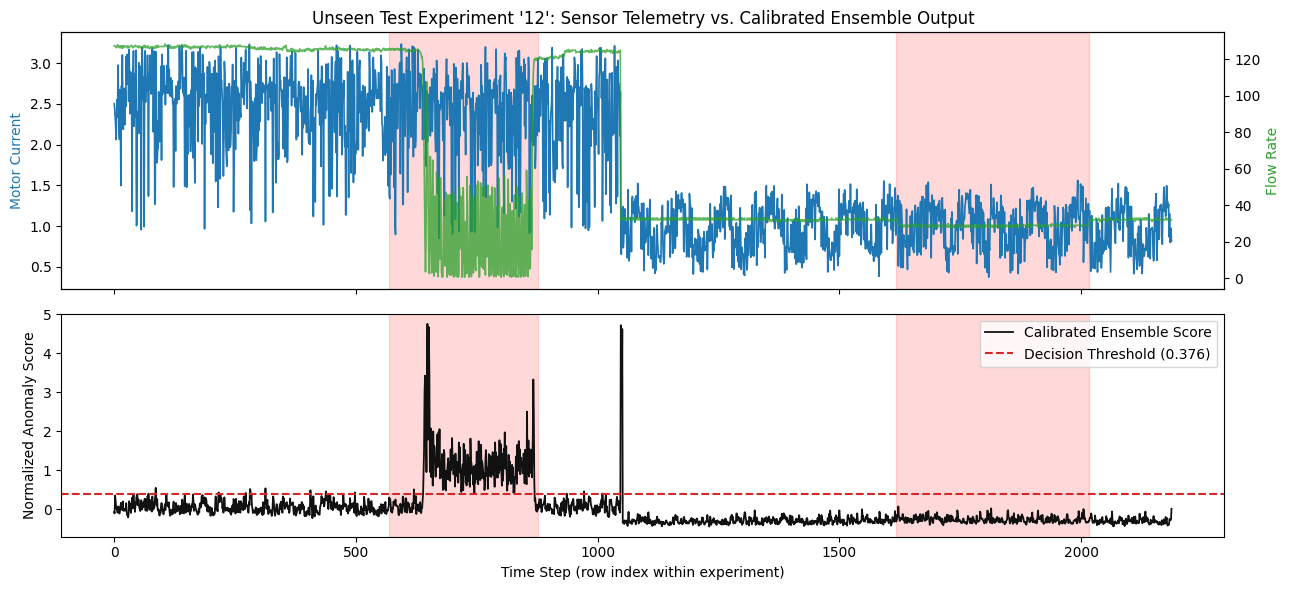

In [34]:
# ==============================================================================
# 15.1.2 End-to-End RAG & Agent Output on Sampled Test Rows
# ==============================================================================
normal_examples  = sample_space[sample_space["EnsemblePrediction"] == 0].head(1)
flagged_examples = sample_space[sample_space["EnsemblePrediction"] == 1].head(2)
demo_subset = pd.concat([normal_examples, flagged_examples]).reset_index(drop=True)

print("=" * 90)
print("END-TO-END MODEL + RAG DIAGNOSTIC OUTPUT ON SAMPLE SPACE")
print("=" * 90)

for _, row in demo_subset.iterrows():
    r_idx = int(row["test_row_idx"])
    row_readings = {c: float(row[c]) for c in numeric_features if pd.notna(row[c])}
    row_votes = {name: int(row[name + "_Prediction"]) for name in normalized_test_scores}
    sample_incident = {
        "experiment_id": str(row["experiment_id"]),
        "ensemble_score": float(row["EnsembleScore"]),
        "model_votes": row_votes,
        "sensor_readings": row_readings,
    }

    report_json, mode = generate_structured_maintenance_report(sample_incident, top_k=3, max_new_tokens=240)
    print(f"\n[Test Row #{r_idx} | Experiment: {row['experiment_id']}]")
    print(f"Ground Truth : {'1 (ANOMALY)' if int(row['anomaly']) == 1 else '0 (NORMAL)'}")
    print(f"Model Output : {'1 (ANOMALY)' if int(row['EnsemblePrediction']) == 1 else '0 (NORMAL)'} "
          f"| EnsembleScore={row['EnsembleScore']:.4f} (Threshold={ens_thresh:.4f}) | Votes={row_votes}")
    print(f"RAG Report ({mode}):")
    print(json.dumps(report_json, indent=2))
    print("-" * 90)

# ==============================================================================
# 15.1.3 Visual Timeline on an Unseen Test Experiment
# ==============================================================================
anom_exps = sample_space[sample_space["anomaly"] == 1]["experiment_id"].unique()
target_exp = anom_exps[0] if len(anom_exps) > 0 else sample_space["experiment_id"].iloc[0]
exp_trace = demo_df[demo_df["experiment_id"] == target_exp].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]}
)

if "Current" in exp_trace.columns:
    ax1.plot(exp_trace.index, exp_trace["Current"], label="Motor Current", color="#1f77b4", linewidth=1.2)
    ax1.set_ylabel("Motor Current", color="#1f77b4")
if "FlowRate" in exp_trace.columns:
    ax1_twin = ax1.twinx()
    ax1_twin.plot(exp_trace.index, exp_trace["FlowRate"], label="Flow Rate", color="#2ca02c", alpha=0.75, linewidth=1.2)
    ax1_twin.set_ylabel("Flow Rate", color="#2ca02c")
ax1.set_title(f"Unseen Test Experiment '{target_exp}': Sensor Telemetry vs. Calibrated Ensemble Output")

in_anom, start_i, labeled = False, 0, False
for i, val in enumerate(exp_trace["anomaly"]):
    if val == 1 and not in_anom:
        start_i, in_anom = i, True
    elif val == 0 and in_anom:
        lbl = "Ground-Truth Anomaly Window" if not labeled else ""
        ax1.axvspan(start_i, i, color="red", alpha=0.15, label=lbl)
        ax2.axvspan(start_i, i, color="red", alpha=0.15)
        in_anom, labeled = False, True
if in_anom:
    lbl = "Ground-Truth Anomaly Window" if not labeled else ""
    ax1.axvspan(start_i, len(exp_trace) - 1, color="red", alpha=0.15, label=lbl)
    ax2.axvspan(start_i, len(exp_trace) - 1, color="red", alpha=0.15)

ax2.plot(exp_trace.index, exp_trace["EnsembleScore"], label="Calibrated Ensemble Score", color="#111111", linewidth=1.3)
ax2.axhline(ens_thresh, color="#d62728", linestyle="--", linewidth=1.5, label=f"Decision Threshold ({ens_thresh:.3f})")
ax2.set_ylabel("Normalized Anomaly Score")
ax2.set_xlabel("Time Step (row index within experiment)")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 16. Save experiment outputs and models

This cell saves the metrics, predictions, calibration thresholds, and fitted classical models. The notebook itself remains the primary reproducibility artifact. For full reproducibility, also record the Colab runtime, package versions, random seed and dataset repository commit.

In [35]:
import joblib

OUTPUT_DIR = Path("/content/industrial_energy_project_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(OUTPUT_DIR / "model_comparison.csv")
test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
pd.Series(calibration_thresholds).to_csv(OUTPUT_DIR / "score_scaling_values.csv")
pd.Series(decision_thresholds).to_csv(OUTPUT_DIR / "validation_selected_thresholds.csv")

joblib.dump(if_model, OUTPUT_DIR / "isolation_forest.joblib")
joblib.dump(knn_model, OUTPUT_DIR / "knn_detector.joblib")
joblib.dump(pca_model, OUTPUT_DIR / "pca_detector.joblib")
joblib.dump(imputer, OUTPUT_DIR / "imputer.joblib")
joblib.dump(scaler, OUTPUT_DIR / "scaler.joblib")
torch.save(ae_model.state_dict(), OUTPUT_DIR / "autoencoder_state_dict.pt")

with open(OUTPUT_DIR / "incident_demo.json", "w") as f:
    json.dump(incident, f, indent=2)

print("Saved files:")
for path in OUTPUT_DIR.iterdir():
    print(path.name, round(path.stat().st_size / 1024, 1), "KB")


# Save CO2/CO3 artifacts when those sections have been executed.
if "co2_extraction" in globals():
    with open(OUTPUT_DIR / "co2_information_extraction.json", "w") as f:
        json.dump(co2_extraction, f, indent=2)
if "page_topics" in globals():
    page_topics.to_csv(OUTPUT_DIR / "co3_lda_page_topics.csv", index=False)
    with open(OUTPUT_DIR / "co3_lda_topic_keywords.json", "w") as f:
        json.dump(TOPIC_KEYWORDS, f, indent=2)


# Save CO4 Extension A & B outputs when executed.
if "structured_report" in globals():
    with open(OUTPUT_DIR / "co4_ext_a_structured_report.json", "w") as f:
        json.dump(structured_report, f, indent=2)
if "agent_result" in globals():
    with open(OUTPUT_DIR / "co4_ext_b_agent_plan.json", "w") as f:
        json.dump(agent_result, f, indent=2)


Saved files:
pca_detector.joblib 5.6 KB
model_comparison.csv 1.0 KB
isolation_forest.joblib 4023.3 KB
imputer.joblib 1.6 KB
score_scaling_values.csv 0.1 KB
test_predictions.csv 6818.0 KB
autoencoder_state_dict.pt 18.7 KB
incident_demo.json 2.3 KB
validation_selected_thresholds.csv 0.2 KB
scaler.joblib 1.4 KB
knn_detector.joblib 3533.6 KB


## 17. Research-paper reporting checklist

Before writing results, run the notebook from top to bottom and replace all illustrative statements with actual measured outputs.

Report:
- Dataset source/version, number of experiment files, selected features, rows and anomaly prevalence.
- Group-based train/test split and the fact that detectors were trained on normal-labelled training rows.
- Hyperparameters and calibration threshold for each detector. State that the KNN training calibration excludes each point's self-neighbour.
- Describe the combination as an **equal-weight ensemble** (arithmetic mean), not a learned/weighted ensemble.
- Disclose that thresholds are calibrated on model-training normal scores; a separate normal validation/calibration subset is a recommended future improvement.
- Precision, recall, F1, balanced accuracy, ROC-AUC and average precision on held-out experiment groups.
- Confusion matrix and per-experiment results.
- RAG chunk size/overlap, embedding model, FAISS similarity method and retrieval `k`.
- Retrieval evaluation using a manually curated question–relevant-document test set (Precision@K, Recall@K, MRR).
- Human evaluation of generated answers for relevance, evidence support, completeness and safety.

**Do not claim the ensemble is better unless the held-out metrics show that it is.** Do not claim energy savings from SKAB alone: this notebook evaluates anomaly detection and evidence-grounded guidance, not a measured before/after energy-saving intervention.

### Additional RAG knowledge-base references
3. U.S. Department of Energy, *Operations & Maintenance Best Practices Guide: Release 3.0* (2010). https://www.energy.gov/sites/default/files/2020/04/f74/omguide_complete_w-eo-disclaimer.pdf
4. SKF, *SKF Bearing Maintenance Handbook*. Official SKF PDF: https://www.skf.com/binaries/pub12/Images/0901d1968013be94-SKF-bearing-maintenance-handbook---10001_1-EN%281%29_tcm_12-463040.pdf

**RAG provenance note:** These external technical references are separate from the SKAB numerical dataset. In the report, identify publisher, document title, access date and the page numbers actually retrieved. Do not claim these documents diagnose the SKAB test rig or establish machine-specific operating limits.


## 18. References and project sources

1. SKAB — Skoltech Anomaly Benchmark, public GitHub repository: https://github.com/waico/SKAB
2. SKAB dataset record: https://doi.org/10.34740/KAGGLE/DSV/1693952
3. Qwen2.5-1.5B-Instruct model card and license: https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
4. Sentence Transformers documentation: https://www.sbert.net/
5. FAISS documentation: https://github.com/facebookresearch/faiss

Check the licenses and usage terms of the dataset and all documents before redistribution or publication.
6. Hugging Face Transformers pipelines: https://huggingface.co/docs/transformers/main_classes/pipelines
7. Google Cloud Translation documentation: https://cloud.google.com/translate/docs
8. scikit-learn Latent Dirichlet Allocation: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html

## NLP Lab demonstration checklist — CO1 to CO4

| CO | Where demonstrated in this notebook | Evidence to show during viva |
|---|---|---|
| CO1 | PDF extraction, page-wise cleaning, chunking, Sentence Transformer embeddings and FAISS vectorization | Extracted page text, chunks, embedding dimension and FAISS vector count |
| CO2 | Transformer sentiment classification, NER and domain-specific information extraction | Operator note, sentiment output, entities, extracted components/symptoms/actions/measurements JSON |
| CO3 | TF-IDF + LDA topic modeling; language detection and optional Google Cloud Translation | Topic keywords, dominant topic per PDF page, detected language and (when configured) translated query + RAG retrieval |
| CO4 | Qwen2.5-1.5B-Instruct, prompt engineering, retrieval-grounded generation and interactive assistant | Retrieved source/page passages and generated answer with evidence citations |
| CO4 Ext A | Structured AI Report Generation (`generate_structured_maintenance_report`) | Validated JSON maintenance report with health status, detected anomalies, possible causes, risk severity, safe recommendations, and citations |
| CO4 Ext B | Agentic AI for Predictive Maintenance (`PredictiveMaintenanceAgent`) | 5-step tool execution trace (sensor check → ensemble detector → FAISS RAG → structured report → prioritized P1/P2/P3 advisory plan) |

**Important demonstration notes:** Run the notebook from top to bottom. The sentiment and NER models download pretrained weights on first use. Google Cloud Translation requires the user's own enabled Google Cloud project and API key; do not publish the key in a shared notebook. If the cloud key is unavailable, demonstrate the complete LDA topic-modeling path for CO3 and clearly state that cloud translation is an optional extension. The illustrative operator note should be replaced with an anonymized real maintenance note if one is available. The sentiment output measures text polarity, not equipment risk or fault severity.